# M13b · Optimisation sous contraintes et SVM — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m13b_lagrange_svm/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M13b.1 à M13b.13, M13b.20 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M13b.25 | Un problème quadratique sous contraintes d'égalité, par le système de Lagrange · `lagrange_equality_qp` | 🔨 | ★ | 20 |
|  | M13b.26 | La hinge loss et un sous-gradient de l'objectif d'une SVM linéaire · `hinge_loss, svm_subgradient` | 🔨 | ★★ | 25 |
|  | M13b.27 | Les noyaux RBF et polynomial · `rbf_kernel, polynomial_kernel` | 🔨 | ★ | 20 |
|  | M13b.28 | `scipy.optimize.minimize` sous contraintes et les noyaux de scikit-learn contre tes fonctions | 📦 | ★ | 15 |
| B | M13b.29 | Prédire : comment change le minimum quand on relâche la contrainte, et ce que dit λ | 🔮 | ★ | 10 |
|  | M13b.30 | La descente de sous-gradient sur la hinge loss : pas constant contre pas décroissant | 🔬 | ★★ | 20 |
|  | M13b.31 | Lignes de niveau et contrainte : voir le point de Lagrange | 🎨 | ★ | 20 |
| C | M13b.32 | Chasse à l'erreur : le signe d'un multiplicateur, une largeur de bande 1/‖w‖ au lieu de 2/‖w‖, une matrice de Gram non symétrique | 🐛 | ★ | 15 |
|  | M13b.33 | Vérifier une solution KKT : faisabilité, stationnarité, complémentarité | 🛠️ | ★ | 15 |
|  | M13b.34 | Défi : une SVM linéaire entraînée par sous-gradient, un objectif à 1 % de celui de scikit-learn au même C | 🏆 | ★★★ | 30 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : Lagrange sous une et deux contraintes d'égalité, la distance à un plan, l'ACP relue par Lagrange, les conditions KKT, une fonction duale, la convexité, une SVM à marge dure, la hinge loss et le sous-gradient, le dual d'une SVM, les noyaux polynomial et RBF, la décision d'une SVM à noyau.
- Écrire les cinq fonctions de `mymath/svm.py` et les tester, puis comparer avec SciPy et scikit-learn.
- Prédire le prix d'une contrainte, comparer des pas de sous-gradient, voir le point de Lagrange, chasser des erreurs de SVM, vérifier une solution KKT, relever un défi d'entraînement.

**Rappel express.** Lagrange : $\nabla f + \lambda\nabla g = \mathbf{0}$ et $g = 0$, et $\frac{df^*}{dc} = -\lambda$ pour $f + \lambda(g - c)$ ; problème quadratique : $\begin{pmatrix} \mathbf{Q} & \mathbf{A}^\top \\ \mathbf{A} & \mathbf{0} \end{pmatrix}\begin{pmatrix} \mathbf{x} \\ \boldsymbol{\lambda} \end{pmatrix} = \begin{pmatrix} -\mathbf{c} \\ \mathbf{b} \end{pmatrix}$ ; KKT ($g_i \le 0$) : stationnarité, faisabilité, $\mu_i \ge 0$, $\mu_i g_i = 0$ ; dual $D(\boldsymbol{\mu}) = \min_{\mathbf{x}} \mathcal{L} \le f^*$ ; SVM : $\min \frac{1}{2}\lVert\mathbf{w}\rVert^2$ sous $y_i(\mathbf{w} \cdot \mathbf{x}_i + b) \ge 1$, marge $\rho = 1/\lVert\mathbf{w}\rVert$, bande $2\rho$ ; $J = \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max(0, 1 - t_i)$, $\mathbf{g}_{\mathbf{w}} = \mathbf{w} - C\sum_{t_i < 1} y_i\mathbf{x}_i$, $g_b = -C\sum_{t_i < 1} y_i$ ; dual : $\mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$, $0 \le \alpha_i \le C$ ; noyaux $(\mathbf{x} \cdot \mathbf{z} + c)^d$ et $e^{-\gamma\lVert\mathbf{x} - \mathbf{z}\rVert^2}$, décision $s(\mathbf{x}) = \sum_i \alpha_i y_i\,k(\mathbf{x}_i, \mathbf{x}) + b$.

## Partie 0 · Vérifier tes exercices papier (✏️ M13b.1 à M13b.13, 🔗 M13b.20)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"5/9"` ;
- une liste `[0.15, -2]` ; dans une liste, une fraction s'écrit comme un calcul, sans guillemets : `[2/9, 7/9]` ; une matrice, comme une liste de lignes : `[[1, 0.5], [0.5, 1]]` ;
- une expression entre guillemets, écrite comme en Python : `"mu**2 - 7*mu"` pour $\mu^2 - 7\mu$ ;
- des lettres collées entre guillemets, `"BD"`, ou `True` / `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly (SymPy) from the statements
import math

import sympy

R, sq = sympy.Rational, sympy.sqrt
mu = sympy.symbols("mu")
xs, ys = sympy.symbols("xs ys", real=True)


def floats(values):
    """SymPy numbers as a list of Python floats."""
    return [float(v) for v in values]


x_, y_, z_, l_, c_ = sympy.symbols("x y z l c", positive=True)                              # M13b.1
SOL_1 = sympy.solve([y_ * z_ - l_, x_ * z_ - 2 * l_, x_ * y_ - 4 * l_, x_ + 2 * y_ + 4 * z_ - c_],
                    [x_, y_, z_, l_], dict=True)[0]      # the stationarity of xyz − λ(x + 2y + 4z − c), and the constraint
PSTAR_1 = sympy.simplify((x_ * y_ * z_).subs(SOL_1))     # P*(c)
POINT_1 = [int(SOL_1[v].subs(c_, 24)) for v in (x_, y_, z_)]
LAM_1 = SOL_1[l_].subs(c_, 24)
N_2, X0_2 = sympy.Matrix([4, -4, 7]), sympy.Matrix([5, 1, 3])                              # M13b.2
P_2 = sympy.Matrix(sympy.symbols("p1:4"))
SOL_2 = sympy.solve(list(2 * (P_2 - X0_2) + mu * N_2) + [(N_2.T * P_2)[0] - 10], list(P_2) + [mu], dict=True)[0]
LAM_2, PROJ_2 = SOL_2[mu], P_2.subs(SOL_2)
Q_3 = sympy.Matrix([[4, 1, 0], [1, 2, 0], [0, 0, 2]])                                       # M13b.3
C_3, A_3, B_3 = sympy.Matrix([-2, 0, 1]), sympy.Matrix([[1, 1, 1], [1, 0, -1]]), sympy.Matrix([3, 1])


def block_3(A):
    """The block matrix [[Q, Aᵀ], [A, 0]] of the constraints A x = b."""
    return sympy.BlockMatrix([[Q_3, A.T], [A, sympy.zeros(A.rows, A.rows)]]).as_explicit()


def solve_3(A, b):
    """(x, λ) of min ½ xᵀQx + cᵀx under A x = b."""
    s = block_3(A).LUsolve(sympy.Matrix.vstack(-C_3, b))
    return s[:3, 0], s[3:, 0]


def obj_3(x, half=R(1, 2)):
    """half · xᵀQx + cᵀx (half = 1/2 for f)."""
    return half * (x.T * Q_3 * x)[0] + (C_3.T * x)[0]


X_3, L_3 = solve_3(A_3, B_3)
X1_3 = solve_3(A_3[0:1, :], B_3[0:1, :])[0]
FREE_3 = -Q_3.inv() * C_3
C_4 = sympy.Matrix([[2, -3, 1], [-3, 10, -3], [1, -3, 8]])                                  # M13b.4
EIG_4 = sorted(C_4.eigenvals(), reverse=True)
V_4 = (C_4 - EIG_4[0] * sympy.eye(3)).nullspace()[0]
U1_4 = V_4 / V_4.norm()
U1_4 = U1_4 * sympy.sign(U1_4[max(range(3), key=lambda i: abs(U1_4[i]))])   # largest coordinate in absolute value > 0
F_5 = xs ** 2 + 2 * ys ** 2 - 4 * xs - 8 * ys                                               # M13b.5
FREE_5 = sympy.solve([sympy.diff(F_5, xs), sympy.diff(F_5, ys)], [xs, ys], dict=True)[0]
SOL_5 = sympy.solve([sympy.diff(F_5, xs) + 2 * mu, sympy.diff(F_5, ys) + mu, 2 * xs + ys - 3], [xs, ys, mu], dict=True)[0]
MU_5, P_5 = SOL_5[mu], [SOL_5[xs], SOL_5[ys]]
GE_5 = sympy.solve([sympy.diff(F_5, xs) - 2 * mu, sympy.diff(F_5, ys) - mu, 3 - 2 * xs - ys], [xs, ys, mu], dict=True)[0]
L_6 = xs ** 2 + 2 * ys ** 2 + mu * (6 - xs - ys)                                             # M13b.6
ARG_6 = sympy.solve([sympy.diff(L_6, xs), sympy.diff(L_6, ys)], [xs, ys], dict=True)[0]
D_6 = sympy.expand(L_6.subs(ARG_6))
MU_6 = sympy.solve(sympy.diff(D_6, mu), mu)[0]
a1, a2, a3, w1, w2, bb = sympy.symbols("a1 a2 a3 w1 w2 bb")                                 # M13b.8
PTS_8 = [((3, 5), 1), ((7, 7), 1), ((7, 2), -1)]
WS_8 = sympy.Matrix([w1, w2])
SOL_8 = sympy.solve(list(WS_8 - sum((a * yy * sympy.Matrix(p) for a, (p, yy) in zip((a1, a2, a3), PTS_8)),
                                    sympy.zeros(2, 1)))
                    + [a1 + a2 - a3] + [yy * ((WS_8.T * sympy.Matrix(p))[0] + bb) - 1 for p, yy in PTS_8],
                    [a1, a2, a3, w1, w2, bb], dict=True)[0]
W_8, B_8 = sympy.Matrix([SOL_8[w1], SOL_8[w2]]), SOL_8[bb]
ALPHA_8 = [SOL_8[a1], SOL_8[a2], SOL_8[a3]]
HALF_8 = (W_8.T * W_8)[0] / 2
W_9, B_9, C_9 = sympy.Matrix([1, R(-1, 2)]), R(1, 2), 2                                     # M13b.9
PTS_9 = [((3, 0), 1), ((1, 0), 1), ((0, R(3, 5)), 1), ((-1, 1), -1), ((2, R(9, 5)), -1), ((-2, R(2, 5)), -1)]
S_9 = [(W_9.T * sympy.Matrix(p))[0] + B_9 for p, _ in PTS_9]
T_9 = [yy * s for s, (_, yy) in zip(S_9, PTS_9)]
H_9 = [sympy.Max(0, 1 - t) for t in T_9]
HALF_9 = (W_9.T * W_9)[0] / 2
W_10, B_10, C_10, ETA_10 = sympy.Matrix([R(1, 2), 1]), -1, R(1, 2), R(1, 5)                 # M13b.10
PTS_10 = [((3, R(1, 2)), 1), ((0, 3), -1), ((1, -1), -1), ((-1, 2), 1)]


def margins_10(w, b):
    """The functional margins y (w · x + b) of the four examples."""
    return [yy * ((w.T * sympy.Matrix(p))[0] + b) for p, yy in PTS_10]


def j_10(w, b, C=C_10):
    """½‖w‖² + C Σ max(0, 1 − t)."""
    return (w.T * w)[0] / 2 + C * sum(sympy.Max(0, 1 - t) for t in margins_10(w, b))


def sub_10(w, b, kink=False):
    """(g_w, g_b), counting the margins < 1 (≤ 1 with kink)."""
    chosen = [(p, yy) for (p, yy), t in zip(PTS_10, margins_10(w, b)) if (t <= 1 if kink else t < 1)]
    g_w = w - C_10 * sum((yy * sympy.Matrix(p) for p, yy in chosen), sympy.zeros(2, 1))
    return g_w, -C_10 * sum(yy for _, yy in chosen)


GW_10, GB_10 = sub_10(W_10, B_10)
GW2_10, GB2_10 = sub_10(W_10, B_10, kink=True)
WNEW_10, BNEW_10 = W_10 - ETA_10 * GW_10, B_10 - ETA_10 * GB_10
PTS_11 = [((5, 6), 1, R(9, 10)), ((3, 7), 1, 1), ((7, 4), 1, 0), ((5, 8), -1, 1), ((1, 5), -1, 0),     # M13b.11
          ((2, 5), -1, R(9, 10))]
W_11 = sum((a * yy * sympy.Matrix(p) for p, yy, a in PTS_11), sympy.zeros(2, 1))
B_11 = 1 - (W_11.T * sympy.Matrix([5, 6]))[0]            # read on the free support vector x₁, of label +1
S_11 = [(W_11.T * sympy.Matrix(p))[0] + B_11 for p, _, _ in PTS_11]
T_11 = [yy * s for s, (_, yy, _) in zip(S_11, PTS_11)]
HALF_11 = (W_11.T * W_11)[0] / 2
HINGE_11 = sum(sympy.Max(0, 1 - t) for t in T_11)
X_12, Z_12 = sympy.Matrix([4, -3]), sympy.Matrix([3, -5])                                   # M13b.12


def phi_12(v, const=1, root=None, first=None, cross=sq(2)):
    """φ(v) of (const + x · z)²: (const, √(2 const) v₁, √(2 const) v₂, v₁², √2 v₁v₂, v₂²); the variants replace the
    coefficient of the degree-1 terms by root, the first coordinate by first, and the √2 of x₁x₂ by cross."""
    root = sq(2 * const) if root is None else root
    first = const if first is None else first
    return sympy.Matrix([first, root * v[0], root * v[1], v[0] ** 2, cross * v[0] * v[1], v[1] ** 2])


def k_12(u, v, const=1):
    """(const + u · v)²."""
    return (const + (u.T * v)[0]) ** 2


assert sympy.simplify((phi_12(X_12).T * phi_12(Z_12))[0] - k_12(X_12, Z_12)) == 0
assert sympy.simplify((phi_12(X_12, 3).T * phi_12(Z_12, 3))[0] - k_12(X_12, Z_12, 3)) == 0


PTS_13 = [sympy.Matrix([0, 0]), sympy.Matrix([3, 0]), sympy.Matrix([0, -2])]                # M13b.13
D2_13 = [[((u - v).T * (u - v))[0] for v in PTS_13] for u in PTS_13]


def gram_13(gamma, squared=True):
    """The RBF Gram matrix e^(−γ d²) of the three points (e^(−γ d) when not squared)."""
    return sympy.Matrix(3, 3, lambda i, j: sympy.exp(-gamma * (D2_13[i][j] if squared else sq(D2_13[i][j]))))


K_13 = gram_13(R(1, 5))
SV_20 = [((-1, 1), 1, R(4, 5)), ((2, -1), -1, R(1, 2)), ((1, 3), -1, R(3, 10))]               # M13b.20
G_20, B_20 = R(3, 10), R(-1, 10)


def s_20(p, bias=B_20, labels=True, squared=True):
    """The decision Σ αᵢ yᵢ e^(−γ‖xᵢ − p‖²) + b (variants: without labels, without the square)."""
    total = bias
    for q, yy, a in SV_20:
        d2 = ((sympy.Matrix(q) - sympy.Matrix(p)).T * (sympy.Matrix(q) - sympy.Matrix(p)))[0]
        total += a * (yy if labels else 1) * sympy.exp(-G_20 * (d2 if squared else sq(d2)))
    return total

**Ex M13b.1 — Lagrange à la main : un produit maximal sous une contrainte linéaire**

In [3]:
wbm.record("M13b.1a", POINT_1, mistakes={"le coefficient 4 rend z « cher » : c'est la plus petite des trois valeurs": [2, 4, 8], "la stationnarité donne yz = λ, xz = 2λ et xy = 4λ : divise ces équations deux à deux": [24 / 7, 24 / 7, 24 / 7]})
wbm.record("M13b.1b", int(PSTAR_1.subs(c_, 24)))
wbm.record("M13b.1c", int(LAM_1), mistakes={"avec ℒ = xyz − λ(x + 2y + 4z − 24), la stationnarité en x donne yz − λ = 0 : regarde le signe de yz": -8})
wbm.record("M13b.1d", int(PSTAR_1.subs(c_, 24) + LAM_1), mistakes={"augmenter le second membre (c passe de 24 à 25) fait MONTER le maximum : P* + λ × 1": 56})
wbm.record("M13b.1e", PSTAR_1.subs(c_, 25), kind="fraction", simplified=True, mistakes={"e) demande la VRAIE valeur, au maximum pour c = 25, pas l'estimation de d)": 72})
wbm.record("M13b.1f", int(sympy.diff(PSTAR_1, c_).subs(c_, 24)), mistakes={"f) demande la DÉRIVÉE de P*(c) en c = 24, pas la valeur P*(24)": 64})
wbm.record("M13b.1g", 12 * 2 * 2, mistakes={"le PRODUIT xyz au point (12, 2, 2), pas la valeur de x + 2y + 4z": 24})

WBM_ANSWER {"decimals": 0, "element_hashes": ["70d3c21cdad01dac427ab6ff866189f0585ef20bb86a8dbd7ecffb39090e7897", "3c0cec06658f0ecf50203ac0991f76515c67563e0003bb88edc25e69d334ed53", "fbc8654390959fc0ec4a21fa81f941469db9e04c9b2029f662f85b6aeb655789"], "hash": "0be0947d7c85a7b054eeac18bc29f991dd346e95d3d658074945bc9c2c9ee87d", "id": "M13b.1a", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": {"576425a99aeb21ed2619ff699dcf6cc8a39857d18bb3087c65c8ef11c2d78169": "le coefficient 4 rend z « cher » : c'est la plus petite des trois valeurs", "c3e23bd037e92559fa52d91f6632875bcb4de5ee2dd6faf6c016e745178d67f0": "la stationnarité donne yz = λ, xz = 2λ et xy = 4λ : divise ces équations deux à deux"}, "shape": [3]}
📝 Ex M13b.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "85c98d7923a761a6d8c7cab38862d97e45a657c6e73f62f356d8ff21cbe56a86", "id": "M13b.1b", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M13b.1b : réponse enregistrée (int).
WBM_ANSWER {"hash": "e22b

**Ex M13b.2 — La distance d'un point à un plan, retrouvée par Lagrange**

In [4]:
wbm.record("M13b.2a", LAM_2, kind="fraction", simplified=True, mistakes={"le gradient de ‖x − x₀‖² est 2(x − x₀) : n'oublie pas le 2": R(1, 3), "avec ℒ = ‖x − x₀‖² + λ(n · x − 10), λ a le signe de n · x₀ − 10": R(-2, 3)})
wbm.record("M13b.2b", floats(PROJ_2), decimals=6, mistakes={"on revient VERS le plan : x = x₀ − (λ/2) n": floats(X0_2 + LAM_2 / 2 * N_2), "la stationnarité 2(x − x₀) + λn = 0 donne x = x₀ − (λ/2) n : n'oublie pas le 2": floats(X0_2 - LAM_2 * N_2)})
wbm.record("M13b.2c", int(((PROJ_2 - X0_2).T * (PROJ_2 - X0_2))[0]), mistakes={"c) demande le minimum de ‖x − x₀‖², le CARRÉ de la distance": 3})
wbm.record("M13b.2d", int(sq(((PROJ_2 - X0_2).T * (PROJ_2 - X0_2))[0])), mistakes={"divise n · x₀ − 10 par ‖n‖, la norme de n": 27, "la distance est la RACINE du minimum de c)": 9})
wbm.record("M13b.2e", int((N_2.T * X0_2)[0]), mistakes={"e) demande n · x₀ seul, sans retrancher le second membre": 27})
wbm.record("M13b.2f", int(N_2.norm()), mistakes={"‖n‖ est la RACINE de 4² + 4² + 7²": 81})

WBM_ANSWER {"hash": "0c860dcc60bb84aaa4873e2e7466bfaab5be1d831508f826979f0ba167247308", "id": "M13b.2a", "kind": "fraction", "mistakes": {"4c500f507ae5d4bae569cba3a5083f3b17cc8593b5bcf3d6c6a28235222e6eda": "le gradient de ‖x − x₀‖² est 2(x − x₀) : n'oublie pas le 2", "a5cbcd305cf4ed24ed19fcc9403502756ef150afcdab45a9b191a0798ba63e55": "avec ℒ = ‖x − x₀‖² + λ(n · x − 10), λ a le signe de n · x₀ − 10"}, "sign": 1, "simplified": true}
📝 Ex M13b.2a : réponse enregistrée (fraction).
WBM_ANSWER {"array_rounded": {"1": "d2a2344dbea6ff5018c5070682cf2f89a2a8c7dac404a00e81261d1789051f65", "2": "57cd11cf9e16cefd6ee1864eccdc6dbc43706e208a11142aa0ac4c14ce0d7508", "3": "51e51d2774925259c952c6474243a1939c2de59ba6fbd34f953bb08c182b6cfd", "4": "d3b341a3d47eabf5c0886f46f02fd320e0581128bb3ca3823e5015d341a6dea9", "5": "b4e5266a9549bcfd1d63a26cfd44c8aad1aac7dbb1af970e4db846604bd3f4d1"}, "decimals": 6, "element_coarse": [["92ed26aa57e00f1bbecce1eb94ae448e08802a59076e481a6963e72afaff8a73"], ["33d75c0f554fb091

**Ex M13b.3 — Un problème quadratique sous deux contraintes linéaires : le système de Lagrange**

In [5]:
wbm.record("M13b.3a", block_3(A_3).rows, mistakes={"une ligne par inconnue ET une par multiplicateur : n + m": {2, 3}})
wbm.record("M13b.3b", floats(X_3), decimals=6, mistakes={"x* respecte les DEUX contraintes, x₁ + x₂ + x₃ = 3 et x₁ − x₃ = 1": floats(X1_3), "le minimum libre −Q⁻¹c ne respecte pas les contraintes : résous le système par blocs": floats(FREE_3)})
wbm.record("M13b.3c", floats(L_3), decimals=6, mistakes={"avec ℒ = f + λᵀ(Ax − b), la stationnarité est Qx + c + Aᵀλ = 0 : attention au signe": floats(-L_3)})
wbm.record("M13b.3d", obj_3(X_3), kind="fraction", simplified=True, mistakes={"f = ½ xᵀQx + cᵀx : n'oublie pas le ½": obj_3(X_3, 1)})
wbm.record("M13b.3e", int(block_3(A_3).det()))
wbm.record("M13b.3f", [int(v) for v in X1_3], mistakes={"f) ne garde que la PREMIÈRE contrainte, x₁ + x₂ + x₃ = 3": floats(X_3)})
wbm.record("M13b.3g", int(obj_3(X1_3)), mistakes={"f = ½ xᵀQx + cᵀx : n'oublie pas le ½": int(obj_3(X1_3, 1))})
wbm.record("M13b.3h", obj_3(FREE_3), kind="fraction", simplified=True, mistakes={"le minimum libre, en x = −Q⁻¹c, vaut −½ cᵀQ⁻¹c : un nombre négatif": -obj_3(FREE_3), "le minimum libre vaut −½ cᵀQ⁻¹c : n'oublie pas le ½": 2 * obj_3(FREE_3)})

WBM_ANSWER {"hash": "f2eaec3604e7614f4399863fbd9a5612691c73b3882a5adf5f61125d2e3fb4bf", "id": "M13b.3a", "kind": "int", "magnitude": 0, "mistakes": {"9cc0923f8bd9e62afbce39a726574e370cc437c8973256a518a6f89ab8254470": "une ligne par inconnue ET une par multiplicateur : n + m", "ee9c6aa81e15536bf5da093c247c5535a2ad5280691cafc5848819d2381a8aaa": "une ligne par inconnue ET une par multiplicateur : n + m"}, "sign": 1}
📝 Ex M13b.3a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 6, "element_coarse": [["ba6aeb1104aeb12e12a2b3bba5bba2c13c6756164a1f892129a25d6183e7fcc4"], ["2951fcb54188ab3484353a75a0d1e19f10233b66b8ecd8c008bd10fc42f3df18"], ["8ab7e91c771998dbf15258f98d1c4059a7d6774f43ce2fa6004f9f6ad489a74e"]], "element_coarse_any": [["3552b61a341dc107815fe697cb60607466ac04807c9e2fed912217f5b620b2db", "c816cfcb7e3bf65aeaf8b78f5f0cbb2e2f4230424f00fe7b117403f167134717", "e1391c1c457b77ae56bdbf8065184502ab1ef29169ef8d57986d0951400d31cb", "1b21cf08a349414c4bde6c8b74fcee80f5d964b42895be77bf8d8af

**Ex M13b.4 — Relire l'ACP par Lagrange : maximiser uᵀCu sous ‖u‖ = 1**

In [6]:
wbm.record("M13b.4a", int(EIG_4[0]), mistakes={"le maximum de uᵀCu sous ‖u‖ = 1 est la PLUS GRANDE valeur propre": {1, 6}})
wbm.record("M13b.4b", floats(U1_4), decimals=4, mistakes={"un axe est UNITAIRE : divise le vecteur propre par sa norme": [-1, 3, -2], "divise par la norme, puis applique la convention : la coordonnée de plus grande valeur absolue est positive": [1, -3, 2], "la convention de M12d : la coordonnée de plus grande valeur absolue est positive": floats(-U1_4)})
wbm.record("M13b.4c", int((U1_4.T * C_4 * U1_4)[0]), mistakes={"u₁ est unitaire : calcule uᵀCu avec le vecteur normalisé de b)": 182})
wbm.record("M13b.4d", 0)
wbm.record("M13b.4e", int(EIG_4[1]), mistakes={"la DEUXIÈME plus grande valeur propre": 1})
wbm.record("M13b.4f", EIG_4[0] / C_4.trace(), kind="fraction", simplified=True, mistakes={"divise par la somme de TOUTES les valeurs propres, la trace de C": R(13, 19)})
wbm.record("M13b.4g", (EIG_4[0] + EIG_4[1]) / C_4.trace(), kind="fraction", simplified=True, mistakes={"les DEUX plus grandes valeurs propres, divisées par la trace": R(7, 10)})
wbm.record("M13b.4h", int(C_4[0, 0]))

WBM_ANSWER {"hash": "f2a6c314950e5494072d0356e459399cdd64ed662dd51061beee877f677dd333", "id": "M13b.4a", "kind": "int", "magnitude": 1, "mistakes": {"72650ac84ad273ddb3e35c08c731737c8ba15174f83714fb83c5a8209d7e2746": "le maximum de uᵀCu sous ‖u‖ = 1 est la PLUS GRANDE valeur propre", "7da4b1111e3065f172fafe8684d15f83542f155e266b1bcc015f21e085e034c7": "le maximum de uᵀCu sous ‖u‖ = 1 est la PLUS GRANDE valeur propre"}, "sign": 1}
📝 Ex M13b.4a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["f6746dd78a2b1ce9e3677347d1d4872ee8097ab0a3cc48e7260b328047cfa8ea"], ["b77b4357aee14d32c4a47408cf55024f2694e82cfcce518fc993bd04809277b6"], ["a48c2e6c4215025e34041b8501df41095334af99f6aa2bea9a2d8d7b644039ae"]], "element_coarse_any": [["8818d4370f03e6ee53ed922545515f9a20024e75067a262f2430f8f2ea4a2dda", "e81dba4276299854625a2d73a259d758a1e90fbe9357fc7f06a1fd16b5c32812"], ["1b95932e864c7277a51fb01eb52dcc830a4824fa401d4cfbf61c5fb98f969241", "ace6d485ff95037ac33e63bad13261d104f09

**Ex M13b.5 — Une contrainte d'inégalité : active ou non, les conditions KKT à la main**

In [7]:
wbm.record("M13b.5a", bool(2 * FREE_5[xs] + FREE_5[ys] <= 3), mistakes={"calcule le minimum libre (∇f = 0), puis teste la contrainte 2x + y ≤ 3": True})
wbm.record("M13b.5b", MU_5, kind="fraction", simplified=True, mistakes={"avec g = 2x + y − c ≤ 0 et ℒ = f + μg, la stationnarité est ∇f + μ∇g = 0 : au minimum, un multiplicateur d'inégalité est positif ou nul": -MU_5})
wbm.record("M13b.5c", floats(P_5), decimals=6, mistakes={"le minimum libre n'est pas admissible pour c = 3 : la contrainte est active": floats([FREE_5[xs], FREE_5[ys]])})
wbm.record("M13b.5d", int(F_5.subs(SOL_5)), mistakes={"pour c = 3, le minimum libre n'est pas admissible : calcule f au point de c)": int(F_5.subs(FREE_5))})
wbm.record("M13b.5e", int(F_5.subs(FREE_5)))
wbm.record("M13b.5f", -MU_5, kind="fraction", simplified=True, mistakes={"df*/dc = −μ : desserrer une contrainte active fait BAISSER le minimum": MU_5})
wbm.record("M13b.5g", GE_5[mu], kind="fraction", simplified=True, mistakes={"écris ℒ = f + μ(3 − 2x − y) : ∇g = (−2, −1), et la stationnarité ∇f + μ∇g = 0 donne le signe de μ": -GE_5[mu]})

WBM_ANSWER {"hash": "85b75be564bdafb9a9a58ef431a0b77122a9d8aa86e7789e84f42c8a2cb6ea06", "id": "M13b.5a", "kind": "bool", "mistakes": {"369cceec38acf080a6c11d20ed715909fdd0944d6e57bb38889716c35468c09c": "calcule le minimum libre (∇f = 0), puis teste la contrainte 2x + y ≤ 3"}}
📝 Ex M13b.5a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "289ab2db7c055748b128df4192516c916891b3b17bfe31c5c416cf8588faa2de", "id": "M13b.5b", "kind": "fraction", "mistakes": {"a1771dd043d8fe2126bfd6f42f78b788a8123d5db15fb0711636f62777bd659f": "avec g = 2x + y − c ≤ 0 et ℒ = f + μg, la stationnarité est ∇f + μ∇g = 0 : au minimum, un multiplicateur d'inégalité est positif ou nul"}, "sign": 1, "simplified": true}
📝 Ex M13b.5b : réponse enregistrée (fraction).
WBM_ANSWER {"array_rounded": {"1": "ea90d3dc1f37e92938abe25f1cb6ec39487428ea0b482922e3d913eaca192443", "2": "1db5c8149f60e321e1ea10600a0e0d0cce2ba2c6b9785524a9b4e45f7d0a9704", "3": "38354ca2e5e52bf514b06bc4a0ca9770b69287fd7056dc3c6317ab2540dca01b", "4": "3

**Ex M13b.6 — La fonction duale d'un petit problème quadratique, et la dualité faible**

In [8]:
wbm.record("M13b.6a", str(D_6), kind="expr", variables=("mu",), mistakes={"D(μ) est ℒ au point qui le minimise en (x, y), avec tous ses termes, −μx − μy compris": str(sympy.expand(D_6 + 3 * mu ** 2 / 4)), "le terme 6μ de ℒ ne dépend pas de (x, y) : il reste dans D(μ)": str(sympy.expand(D_6 - 6 * mu))})
wbm.record("M13b.6b", int(D_6.subs(mu, 4)))
wbm.record("M13b.6c", int(MU_6))
wbm.record("M13b.6d", int(D_6.subs(mu, MU_6)))
wbm.record("M13b.6e", [int(ARG_6[xs].subs(mu, MU_6)), int(ARG_6[ys].subs(mu, MU_6))], mistakes={"x* d'abord, puis y*": [int(ARG_6[ys].subs(mu, MU_6)), int(ARG_6[xs].subs(mu, MU_6))]})
wbm.record("M13b.6f", int((xs ** 2 + 2 * ys ** 2).subs({xs: ARG_6[xs].subs(mu, MU_6), ys: ARG_6[ys].subs(mu, MU_6)})))
wbm.record("M13b.6g", int(D_6.subs(mu, 12)), mistakes={"calcule D(12) avec la formule de a) : la dualité faible dit seulement D(μ) ≤ f*": int(D_6.subs(mu, MU_6))})

WBM_ANSWER {"hash": "c08f857b4ac11947a8fcc99d47688a35a7dae46f2c225e6318eb9aa6798f2832", "id": "M13b.6a", "kind": "expr", "mistakes": {"87212e93e8814a3f73ad0e0a03abe0de60c86f4850de0a6196a3229c64d21b57": "le terme 6μ de ℒ ne dépend pas de (x, y) : il reste dans D(μ)", "a781581cc6519bc92333eafeb5f93432a7e09c9f2578f915eaeb4047d3b80c55": "D(μ) est ℒ au point qui le minimise en (x, y), avec tous ses termes, −μx − μy compris"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["mu"]}
📝 Ex M13b.6a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "57ed3853979cede813fbc3c57f7aa0cf348a53eeea6bf67c4f58db27166179da", "id": "M13b.6b", "kind": "int", "magnitude": 1, "sign": 1}
📝 Ex M13b.6b : réponse enregistrée (int).
WBM_ANSWER {"hash": "ef9bfcd5dad5254a7dd81cb0e54f249305b384cbd590e53c50d90fe93b127298", "id": "M13b.6c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M13b.6c : réponse enregistrée (int).
WBM_ANSWER {"hash": "73c0834ff678d7e1122d20caaf757320e1c199d601560cfad4f203

**Ex M13b.7 — Reconnaître un problème convexe : fonctions, contraintes, ensembles**

In [9]:
wbm.record("M13b.7a", "ADFH", mistakes={"(A) est convexe : x + y ≥ 1 s'écrit 1 − x − y ≤ 0, une contrainte affine": "DFH",
                     "(D) est convexe : eˣ + y² est convexe, et x − y = 2 est une égalité affine": "AFH",
                     "(F) est convexe : −ln est convexe sur ]0, +∞[, et ses contraintes sont affines": "ADH",
                     "(H) est convexe : max(0, 1 − x) est un maximum de fonctions affines, et une somme de fonctions convexes est convexe": "ADF",
                     "(B) n'est pas convexe : x² + y² ≥ 1 décrit l'extérieur d'un disque": "ABDFH",
                     "(C) n'est pas convexe : on y MAXIMISE une fonction convexe": "ACDFH",
                     "(E) n'est pas convexe : l'égalité x² + y² = 4 n'est pas affine": "ADEFH",
                     "(G) n'est pas convexe : la hessienne de x² − y² n'est pas semi-définie positive": "ADFGH",
                     "(B) n'est pas convexe : x² + y² ≥ 1 décrit l'extérieur d'un disque ; et (A) est convexe : x + y ≥ 1 s'écrit 1 − x − y ≤ 0, une contrainte affine": "BDFH",
                     "(C) n'est pas convexe : on y MAXIMISE une fonction convexe ; et (A) est convexe : x + y ≥ 1 s'écrit 1 − x − y ≤ 0, une contrainte affine": "CDFH",
                     "(E) n'est pas convexe : l'égalité x² + y² = 4 n'est pas affine ; et (A) est convexe : x + y ≥ 1 s'écrit 1 − x − y ≤ 0, une contrainte affine": "DEFH",
                     "(G) n'est pas convexe : la hessienne de x² − y² n'est pas semi-définie positive ; et (A) est convexe : x + y ≥ 1 s'écrit 1 − x − y ≤ 0, une contrainte affine": "DFGH",
                     "(B) n'est pas convexe : x² + y² ≥ 1 décrit l'extérieur d'un disque ; et (D) est convexe : eˣ + y² est convexe, et x − y = 2 est une égalité affine": "ABFH",
                     "(C) n'est pas convexe : on y MAXIMISE une fonction convexe ; et (D) est convexe : eˣ + y² est convexe, et x − y = 2 est une égalité affine": "ACFH",
                     "(E) n'est pas convexe : l'égalité x² + y² = 4 n'est pas affine ; et (D) est convexe : eˣ + y² est convexe, et x − y = 2 est une égalité affine": "AEFH",
                     "(G) n'est pas convexe : la hessienne de x² − y² n'est pas semi-définie positive ; et (D) est convexe : eˣ + y² est convexe, et x − y = 2 est une égalité affine": "AFGH",
                     "(B) n'est pas convexe : x² + y² ≥ 1 décrit l'extérieur d'un disque ; et (F) est convexe : −ln est convexe sur ]0, +∞[, et ses contraintes sont affines": "ABDH",
                     "(C) n'est pas convexe : on y MAXIMISE une fonction convexe ; et (F) est convexe : −ln est convexe sur ]0, +∞[, et ses contraintes sont affines": "ACDH",
                     "(E) n'est pas convexe : l'égalité x² + y² = 4 n'est pas affine ; et (F) est convexe : −ln est convexe sur ]0, +∞[, et ses contraintes sont affines": "ADEH",
                     "(G) n'est pas convexe : la hessienne de x² − y² n'est pas semi-définie positive ; et (F) est convexe : −ln est convexe sur ]0, +∞[, et ses contraintes sont affines": "ADGH",
                     "(B) n'est pas convexe : x² + y² ≥ 1 décrit l'extérieur d'un disque ; et (H) est convexe : max(0, 1 − x) est un maximum de fonctions affines, et une somme de fonctions convexes est convexe": "ABDF",
                     "(C) n'est pas convexe : on y MAXIMISE une fonction convexe ; et (H) est convexe : max(0, 1 − x) est un maximum de fonctions affines, et une somme de fonctions convexes est convexe": "ACDF",
                     "(E) n'est pas convexe : l'égalité x² + y² = 4 n'est pas affine ; et (H) est convexe : max(0, 1 − x) est un maximum de fonctions affines, et une somme de fonctions convexes est convexe": "ADEF",
                     "(G) n'est pas convexe : la hessienne de x² − y² n'est pas semi-définie positive ; et (H) est convexe : max(0, 1 − x) est un maximum de fonctions affines, et une somme de fonctions convexes est convexe": "ADFG",
                     "plusieurs problèmes convexes manquent : examine l'objectif, chaque inégalité et chaque égalité": {"A", "D", "F", "H", "AD", "AF", "AH", "DF", "DH", "FH"},
                     "il manque des problèmes convexes, et certains que tu cites ne le sont pas : examine l'objectif, chaque inégalité et chaque égalité de chacun": {"B", "C", "E", "G", "AB", "AC", "AE", "AG", "BC", "BD", "BE", "BF", "BG", "BH", "CD", "CE", "CF", "CG", "CH", "DE", "DG", "EF", "EG", "EH", "FG", "GH", "ABC", "ABD", "ABE", "ABF", "ABG", "ABH", "ACD", "ACE", "ACF", "ACG", "ACH", "ADE", "ADG", "AEF", "AEG", "AEH", "AFG", "AGH", "BCD", "BCE", "BCF", "BCG", "BCH", "BDE", "BDF", "BDG", "BDH", "BEF", "BEG", "BEH", "BFG", "BFH", "BGH", "CDE", "CDF", "CDG", "CDH", "CEF", "CEG", "CEH", "CFG", "CFH", "CGH", "DEF", "DEG", "DEH", "DFG", "DGH", "EFG", "EFH", "EGH", "FGH", "ABCD", "ABCE", "ABCF", "ABCG", "ABCH", "ABDE", "ABDG", "ABEF", "ABEG", "ABEH", "ABFG", "ABGH", "ACDE", "ACDG", "ACEF", "ACEG", "ACEH", "ACFG", "ACGH", "ADEG", "AEFG", "AEGH", "BCDE", "BCDF", "BCDG", "BCDH", "BCEF", "BCEG", "BCEH", "BCFG", "BCFH", "BCGH", "BDEF", "BDEG", "BDEH", "BDFG", "BDGH", "BEFG", "BEFH", "BEGH", "BFGH", "CDEF", "CDEG", "CDEH", "CDFG", "CDGH", "CEFG", "CEFH", "CEGH", "CFGH", "DEFG", "DEGH", "EFGH", "ABCDE", "ABCDF", "ABCDG", "ABCDH", "ABCEF", "ABCEG", "ABCEH", "ABCFG", "ABCFH", "ABCGH", "ABDEF", "ABDEG", "ABDEH", "ABDFG", "ABDGH", "ABEFG", "ABEFH", "ABEGH", "ABFGH", "ACDEF", "ACDEG", "ACDEH", "ACDFG", "ACDGH", "ACEFG", "ACEFH", "ACEGH", "ACFGH", "ADEFG", "ADEGH", "AEFGH", "BCDEF", "BCDEG", "BCDEH", "BCDFG", "BCDFH", "BCDGH", "BCEFG", "BCEFH", "BCEGH", "BCFGH", "BDEFG", "BDEFH", "BDEGH", "BDFGH", "BEFGH", "CDEFG", "CDEFH", "CDEGH", "CDFGH", "CEFGH", "DEFGH", "ABCDEF", "ABCDEG", "ABCDEH", "ABCDFG", "ABCDGH", "ABCEFG", "ABCEFH", "ABCEGH", "ABCFGH", "ABDEFG", "ABDEGH", "ABEFGH", "ACDEFG", "ACDEGH", "ACEFGH", "BCDEFG", "BCDEFH", "BCDEGH", "BCDFGH", "BCEFGH", "BDEFGH", "CDEFGH", "ABCDEFG", "ABCDEGH", "ABCEFGH", "BCDEFGH"},
                     "plusieurs problèmes que tu cites ne sont pas convexes : examine l'objectif, chaque inégalité et chaque égalité": {"ABCDFH", "ABDEFH", "ABDFGH", "ACDEFH", "ACDFGH", "ADEFGH", "ABCDEFH", "ABCDFGH", "ABDEFGH", "ACDEFGH", "ABCDEFGH"}})

WBM_ANSWER {"hash": "cb4eac804ba9a1a2afb20d5d11174eaa9c8f2e48f79c81a891156100314732c8", "id": "M13b.7a", "kind": "str", "mistakes": {"0331efc82aac095333c7f41147466c5a5d7864e947190df220a98a0030e6782a": "il manque des problèmes convexes, et certains que tu cites ne le sont pas : examine l'objectif, chaque inégalité et chaque égalité de chacun", "09182ce9722a5be34780a78f1d766932b3e56b093515ba527db64a1cad261ec7": "il manque des problèmes convexes, et certains que tu cites ne le sont pas : examine l'objectif, chaque inégalité et chaque égalité de chacun", "09ed9499cf89d2d0a2303ed833588c65a84f85889017ec762fc8e0d2f658bf7e": "il manque des problèmes convexes, et certains que tu cites ne le sont pas : examine l'objectif, chaque inégalité et chaque égalité de chacun", "0a259d9a563d4da2d4c37925be232ed1024618391a5e0f7aa11a2785dc0df652": "il manque des problèmes convexes, et certains que tu cites ne le sont pas : examine l'objectif, chaque inégalité et chaque égalité de chacun", "0bf84f2e0f8dd61da3

**Ex M13b.8 — Une SVM à marge dure sur trois points, résolue par les conditions KKT**

In [10]:
wbm.record("M13b.8a", floats(W_8), decimals=6, mistakes={"w pointe vers la classe +1 : vérifie y₁(w · x₁ + b) = 1": floats(-W_8)})
wbm.record("M13b.8b", float(B_8), decimals=6, mistakes={"vérifie y₃(w · x₃ + b) = 1, avec le label y₃ = −1": float(-B_8)})
wbm.record("M13b.8c", floats(ALPHA_8), decimals=6, mistakes={"les αᵢ d'une SVM sont positifs : w = Σ αᵢ yᵢ xᵢ porte déjà le label": floats([ALPHA_8[0], ALPHA_8[1], -ALPHA_8[2]])})
wbm.record("M13b.8d", float(HALF_8), decimals=6, mistakes={"½‖w‖² : n'oublie pas le ½": float(2 * HALF_8)})
wbm.record("M13b.8e", float(1 / sq(2 * HALF_8)), decimals=4, mistakes={"la marge est ρ = 1/‖w‖ ; la bande, deux fois plus large": float(2 / sq(2 * HALF_8)), "la marge est 1/‖w‖, pas ‖w‖": float(sq(2 * HALF_8)), "ρ = 1/‖w‖, avec la racine : ‖w‖ = √(w₁² + w₂²)": float(1 / (2 * HALF_8))})
wbm.record("M13b.8f", float((W_8.T * sympy.Matrix([0, 8]))[0] + B_8), decimals=6, mistakes={"t = y(w · x + b) : n'oublie pas le biais": float((W_8.T * sympy.Matrix([0, 8]))[0])})
wbm.record("M13b.8g", sum(1 for a in ALPHA_8 if a > 0), mistakes={"g) compte les vecteurs de support de la SVM des trois exemples : le quatrième de f) n'en fait pas partie": 4})
wbm.record("M13b.8h", float(sum(ALPHA_8) - HALF_8), decimals=6, mistakes={"le dual retranche ½‖w‖² à Σ αᵢ": float(sum(ALPHA_8))})

WBM_ANSWER {"decimals": 6, "element_coarse": [["c6020a6430a8b16e98840c1bfe2acbed6ed831867f5884780627d9b4b7edd67a"], ["e64b0b3b43821f79b8a4b9275b8d0a9f6ee432a10a13313ef3e3a538122f3144"]], "element_coarse_any": [["5167d414629a5c503801a30b2412cea38423f41cea3235ee52800b53c0a2104c", "04cd3b45679a239d2edfda712616dd43917095ec9e5bdde5f6e94939ddb06b35", "ff6c5b2e48502ee2b2442c6d9b8936c532a1e732246855bf8228463b2293cfcc", "be4155de215c83b8efb858cd08f8576c0d7f05315ed34a1453a95e3c5ad33ced"], ["8d834265284306bb14f40144275f518a73a3150c34bd7b94f848e0c98ea76835", "2c9fed36d32ea5a389b1fe5ef30eef5139f315b8725878152f7bc8d940099558", "e4c87c7ffd4a655569639820837e2dafea4848022865b50d449d4c88bc2462d5", "b43611a53cb7beb8b8dd8f452c3c0eb38a2d4a16e95b8c86dd531538e5c4ed6b"]], "element_hashes": ["2a13669ecc04cbf58a696f4fd77412f02d6157949e43ed91bbb57acd178991a3", "473eec35d1fcdabee82de0b3cd1fdbb0b2770f22f975b4542c29e2faca3742d3"], "hash": "debe3694d22095c12e490b40685616109ef540aeb2e14b465a57b3f969379e83", "id": "M1

**Ex M13b.9 — La hinge loss et l'objectif régularisé de quelques points**

In [11]:
wbm.record("M13b.9a", floats(T_9), decimals=6, mistakes={"t = y(w · x + b) : n'oublie pas le biais": floats(yy * (s - B_9) for s, (_, yy) in zip(S_9, PTS_9)), "la marge fonctionnelle multiplie le score par le label y": floats(S_9)})
wbm.record("M13b.9b", floats(H_9), decimals=6, mistakes={"max(0, 1 − t) n'est jamais négatif": floats(1 - t for t in T_9)})
wbm.record("M13b.9c", float(sum(H_9) / 6), decimals=4, mistakes={"la hinge MOYENNE : divise la somme par 6": float(sum(H_9))})
wbm.record("M13b.9d", float(HALF_9), decimals=6, mistakes={"½‖w‖² : n'oublie pas le ½": float(2 * HALF_9)})
wbm.record("M13b.9e", float(HALF_9 + C_9 * sum(H_9)), decimals=6, mistakes={"C multiplie la SOMME des hinges dans J, pas leur moyenne": float(HALF_9 + C_9 * sum(H_9) / 6), "J = ½‖w‖² + C Σ max(0, 1 − tᵢ) : n'oublie pas C": float(HALF_9 + sum(H_9)), "½‖w‖² : n'oublie pas le ½": float(2 * HALF_9 + C_9 * sum(H_9))})
wbm.record("M13b.9f", R(1, 6 * C_9), kind="fraction", simplified=True, mistakes={"λ = 1/(nC) : divise aussi par C": R(1, 6), "λ = 1/(nC) : divise aussi par n": R(1, 2), "λ = 1/(nC), pas nC": 12})
wbm.record("M13b.9g", sum(1 for t in T_9 if t < 1), mistakes={"« strictement » sous 1 : une marge égale à 1 ne compte pas": 3})
wbm.record("M13b.9h", sum(1 for t in T_9 if t < 0), mistakes={"mal classé veut dire t < 0 ; un exemple de marge 0 < t < 1 est bien classé": 2})

WBM_ANSWER {"decimals": 6, "element_coarse": [["ca51afd22619c28f4bc41f96aa3170037dc93ba2a3dd27edde13b1720ff458d7"], ["55aeb6a97a613c2f4b128023330d450550db4b8d9efbd157eb0b6ab3df6bb580"], ["74b8a01154935faa90e92c6b63daa11c3d0f2622b3eaed164280177243e1378f"], ["893d1173c9d9824d87d71254d40defc0fc82b0f1541c1c8a43a983dd1883d4cf"], ["28d99c07a7294fb2fcc684f47cf969749238fdc34d722a03c6370961f9648849"], ["ba18231a523a6e86def4c04cfd78d9cf5d0368a0357fc3e7192c0e245925113c"]], "element_coarse_any": [["c8f313d10f668d29e3c01e9524e01b2b19fe413e92b0f11fa908656e2f95cd77", "42fc346c0814124103331a20ce3255dacac41409633e3bf48a635ccc31ca86a7", "398c43926d2817a16313bf6fc13b9078ab7d5fa5a77b192db5f85e1609da4936", "18038550aaeb86d30a931bec2de3730c6c550c634b9be5ac2eb049ef88e28de9", "a41baa059482201319700ad757de31ec1539b32cdca450a565fb09a6785b04e8"], ["0a4fe61369d7390523f7da775284a7074ecf3f68174071c82fc59df8afb42ed1", "128be2cba60bd7c8a40aa51dba5b7dc85ef089a0bdecc05da55e5230b9ab7099", "6ca3908144b62e73b7215a55b1059e

**Ex M13b.10 — Un pas de sous-gradient sur l'objectif d'une SVM linéaire**

In [12]:
wbm.record("M13b.10a", floats(margins_10(W_10, B_10)), decimals=6, mistakes={"t = y(w · x + b) : n'oublie pas le biais": floats(margins_10(W_10, 0))})
wbm.record("M13b.10b", float(j_10(W_10, B_10)), decimals=4, mistakes={"C multiplie la SOMME des hinges dans J, pas leur moyenne": float(j_10(W_10, B_10, C_10 / 4)), "J = ½‖w‖² + C Σ max(0, 1 − tᵢ) : n'oublie pas C": float(j_10(W_10, B_10, 1))})
wbm.record("M13b.10c", floats(GW_10), decimals=6, mistakes={"ne compte que les marges STRICTEMENT sous 1 : un exemple exactement sur un bord n'entre pas": floats(GW2_10), "g_w commence par w, le gradient de ½‖w‖²": floats(GW_10 - W_10)})
wbm.record("M13b.10d", float(GB_10), decimals=6, mistakes={"ne compte que les marges STRICTEMENT sous 1 : un exemple exactement sur un bord n'entre pas": float(GB2_10)})
wbm.record("M13b.10e", floats(WNEW_10), decimals=6, mistakes={"on descend : w − η g_w, pas w + η g_w": floats(W_10 + ETA_10 * GW_10)})
wbm.record("M13b.10f", float(j_10(WNEW_10, BNEW_10)), decimals=4, mistakes={"on descend : (w, b) − η (g_w, g_b)": float(j_10(W_10 + ETA_10 * GW_10, B_10 + ETA_10 * GB_10))})
wbm.record("M13b.10g", floats(GW2_10), decimals=6, mistakes={"g) compte AUSSI l'exemple de marge exactement 1": floats(GW_10)})

WBM_ANSWER {"decimals": 6, "element_coarse": [["b0a5bf81e93f4945414e4b139bd33b3e03317e2eb15c09440ade4d6227d8e5a3"], ["44ec45c69650d8a3a456a04afe4bf8427922cd49d9ecf0a8e3e15f3d3c72e8b1"], ["ad2389baca100641584d0f890b1c00258946251bba21c87be533b3a0398a432d"], ["c12b6a2be8addf1bd1cb30d9b132a071201f87159e1332fb126c0bbe6ef9f8cc"]], "element_coarse_any": [["119ca3fb35da021b9a4f137bfa6941f65038ebaf3da570fcd3be7e253c9b2c0f", "c123879aeeb958ffd7e2fd7c538b7658bec05e148fe56e9fe311219ce9caa3a0", "3a5535b606f21a87e3e886dd804ebcb29f87b976c292374bef03238cb5f0c452", "8049649e306a69e76c732fc1efb16f0f9a758981eb3fab96ffb46504567a6efc", "465fb40b00963cf57d97545ef196d75781f25bfa87e02139cb3123a52188e531"], ["ad3010cf17679ecd61d65f77aa5fe7836ea6014a582095ffe533963f13f7bc73", "3019c50bb32073066d174a3f3c71a3c47d4dca66eb529b8c782fcdde65c29efa", "546197c70b99b7717791c70aa92be5d75e8f7bcc3903f9e2381cd968797dc705", "d44147f65f079615fdbb8d75a3d3fc27e01bdb59df8107c7a29de439a80f43e3", "a5a6bf5e045a96327520f2a38e509e90ea

**Ex M13b.11 — Le dual d'une SVM : lire les vecteurs de support et retrouver w**

In [13]:
wbm.record("M13b.11a", float(sum(a * yy for _, yy, a in PTS_11)), decimals=6, mistakes={"Σ αᵢ yᵢ, avec les labels": float(sum(a for _, _, a in PTS_11))})
wbm.record("M13b.11b", floats(W_11), decimals=6, mistakes={"w = Σ αᵢ yᵢ xᵢ : le label yᵢ compte": floats(sum((a * sympy.Matrix(p) for p, _, a in PTS_11), sympy.zeros(2, 1)))})
wbm.record("M13b.11c", float(B_11), decimals=6, mistakes={"b se lit sur un vecteur de support LIBRE (0 < αᵢ < C), le seul exactement sur un bord": {float(1 - (W_11.T * sympy.Matrix([3, 7]))[0]), float(-1 - (W_11.T * sympy.Matrix([5, 8]))[0])}})
wbm.record("M13b.11d", [i + 1 for i, (_, _, a) in enumerate(PTS_11) if a > 0], mistakes={"les vecteurs de support sont TOUS les exemples où αᵢ > 0, les bornés (αᵢ = C) compris": [1, 6], "les vecteurs de support sont tous les exemples où αᵢ > 0, les libres (0 < αᵢ < C) compris": [2, 4]})
wbm.record("M13b.11e", floats(T_11), decimals=6, mistakes={"la marge fonctionnelle multiplie le score par le label y": floats(S_11)})
wbm.record("M13b.11f", float(HALF_11 + HINGE_11), decimals=6, mistakes={"C multiplie la SOMME des hinges dans J, pas leur moyenne": float(HALF_11 + HINGE_11 / 6), "½‖w‖² : n'oublie pas le ½": float(2 * HALF_11 + HINGE_11)})
wbm.record("M13b.11g", float(sum(a for _, _, a in PTS_11) - HALF_11), decimals=6, mistakes={"le dual retranche ½‖w‖² à Σ αᵢ": float(sum(a for _, _, a in PTS_11)), "le dual retranche ½‖w‖², avec le ½": float(sum(a for _, _, a in PTS_11) - 2 * HALF_11)})

WBM_ANSWER {"decimals": 6, "hash": "5e1b5541e2d7aab98ac04f8cf0d58697529fe7397edcabcef43d118a1406a65c", "hash_coarse": "988d5eef75c6291fb45cf3c5eb027d5bb031b74095ad40ba76d9f441aa51b7f4", "id": "M13b.11a", "kind": "float", "magnitude": null, "mistakes": {"f7500cc0a7ac921cf514d0311bea114aae349ec3e2bda12b9a506c59e8c27d5c": "Σ αᵢ yᵢ, avec les labels"}, "sign": 0}
📝 Ex M13b.11a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"decimals": 6, "element_coarse": [["d04a70cd06b44f44121c989f33fb7dd02e81ff6c68592e0f43793a49d62b596c"], ["d678d2d20050403532d6dc0622b57ba581a990da006c9fd02d52087ea51bab7d"]], "element_coarse_any": [["6e76b5ba1250d7cc3d90e35c69d13ec916fe37e92f06460bb81dbf2d33f8d0f8", "4fae5da2e7dde02cb8e35e47c64e49209cba6fd2a34fe63272741d1137ff3105", "e03354a7cf9c4a212987dac2f7ac103cb96cc44fc1e6318a2664c14901c67197", "6d1d6e24213b379d1ff1c9386af560902b00cae7c00cd8cff7f282dc1ba202d5", "242229afb50633ccd319395b76c4ca7cd03aa2fed7d1e1f3a1323a316c93bd27"], ["dbd82bf6cbf510aa0360836156e

**Ex M13b.12 — Le noyau (1 + x · z)² en dimension 2 : sa fonction φ à six coordonnées**

In [14]:
wbm.record("M13b.12a", floats(phi_12(X_12)), decimals=2, mistakes={"les √2 de φ ne sont pas décoratifs : ils font sortir les doubles produits": floats(phi_12(X_12, root=1, cross=1))})
wbm.record("M13b.12b", floats(phi_12(Z_12)), decimals=2, mistakes={"les √2 de φ ne sont pas décoratifs : ils font sortir les doubles produits": floats(phi_12(Z_12, root=1, cross=1))})
wbm.record("M13b.12c", int(k_12(X_12, Z_12)), mistakes={"k = (1 + x · z)² : n'oublie pas le 1": int((X_12.T * Z_12)[0] ** 2)})
wbm.record("M13b.12d", floats(phi_12(X_12, const=3)), decimals=2, mistakes={"pour (c + x · z)², les termes de degré 1 ont le coefficient √(2c), ici √6": floats(phi_12(X_12, const=3, root=sq(2))), "la première coordonnée de φ est c = 3 : c × c donne le terme constant c² du développement": floats(phi_12(X_12, const=3, first=1))})
wbm.record("M13b.12e", math.comb(9 + 2, 2), mistakes={"la constante 1 du développement est aussi une coordonnée de φ": math.comb(11, 2) - 1, "(1 + x · z)² contient les monômes de degré 0, 1 ET 2": math.comb(10, 2), "xᵢxⱼ et xⱼxᵢ sont le même monôme : compte chaque paire une fois": 1 + 9 + 9 ** 2})
wbm.record("M13b.12f", math.comb(9 + 3, 3), mistakes={"la constante 1 du développement est aussi une coordonnée de φ": math.comb(12, 3) - 1, "(1 + x · z)³ contient les monômes de degré 0 à 3, pas seulement ceux de degré 3": math.comb(11, 3), "un monôme ne dépend pas de l'ordre de ses facteurs : compte chacun une fois": 1 + 9 + 9 ** 2 + 9 ** 3})

WBM_ANSWER {"decimals": 2, "element_coarse": [["121f22a8493d81f58029ea35436f5392e059c134dca1e0294c3dec5814b4e29e"], ["8310e4910781102c04a55ea42463c736c39700e82e9578f696e3e2876c093998"], ["eb41676449ce357302939b9f4c400d9c6534e258f9e29cf4bd40c49aaa8ce055"], ["4f115377f27d0c5395c5066d070fe3ba01c55de3799c4d77538855e1294a7efd"], ["e68558cf59153afb6a1404847ed87e45362271cf84ca2d54cd4b19e8951777d4"], ["85171794cdf9525c631b4983a9802883440c26f38426c82d683469fe96e7c56c"]], "element_coarse_any": [["84b18b4274f15ea3f912cf16d25d51bf3bf78beb4e052522f66fe7fa8320f6e8"], ["1bb52e5a8b52f6dc84a733d6e7f6a39eb78f9bdd6092b67112c98c32f54e9ecd"], ["6193b9ece9b0270699310c4e7d158fae641a1420d3128ae82ff1acc509eb76b0"], ["27149fbe3c451334ca433951e2415f4f35da8b3ab7088de8426c67b971070aaf"], ["fe827120672923f82878d17220bbfac2d2e32862f14dfdf67c3f51da1d6fc528"], ["c76ecec7364484d29ae7d1b83d48cec6457c1fb66db5c59f2bc55dc1e586e714"]], "element_hashes": ["b4c7097617c64b7bd9287588e935babbff039ac34dfb148b9096d41dc1b77e2b", "d

WBM_ANSWER {"decimals": 2, "element_coarse": [["307eca4759b4df42113f82334a9aeb18c1ce2607dbdc743378935da07fbc3912"], ["1719e36fd772f675dec577e0ad53c8695374fe4cddc97c92c4e80b3541ef1e03"], ["beb583dbab32b441f278af83f6973eb2ce9df6bcdd21a596608d13124c8131ce"], ["b45bb0e14b92b1b99866bd071b2987878353d1fdea01901e49e939895e6a28d9"], ["cc4aff6ed147cdf685aaf8e3e6e5902f8491fed73302b44116f875c510aacda0"], ["7db104cf1c43b594979f57a8ec97dd50252f196c51321f1df3688dfa7a07d6dc"]], "element_coarse_any": [["cfd903c4f52a9e052c271bcba29c245901b185cba160d5d50c2c8ad4c24a2e39"], ["52da8ef6861bb9e85de9ac9262236c435b1d9789183870b4624f4b1005f568d6"], ["e450c31636a00483de4a2b499e9532363b9c92407cb82a12a3cec00b62ec9701"], ["3a56ef24feda29f34ddeca1bdf1df2a44b117fe4d56b3c540933838f896bccc2"], ["2d966a31f46afecedaa9882116e5835bf2780d26fcbadcb6ab9ad2aba2da04cc"], ["9c2cebf23ceefab3253bf7773da5187915101884d18ff14374a5b0aa12d8108b"]], "element_hashes": ["b4d1524dfce57d510b789590386b0095bfe46093ae20ba0e89930fd9c0014e9e", "4

**Ex M13b.13 — La matrice de Gram d'un noyau RBF sur trois points, et l'effet de γ**

In [15]:
wbm.record("M13b.13a", [int(D2_13[0][1]), int(D2_13[0][2]), int(D2_13[1][2])], mistakes={"les CARRÉS des distances, sans racine": floats(sq(d) for d in (D2_13[0][1], D2_13[0][2], D2_13[1][2]))})
wbm.record("M13b.13b", float(K_13[0, 1]), decimals=4, mistakes={"le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": float(gram_13(R(1, 5), squared=False)[0, 1]), "e^(−γ d²) : γ MULTIPLIE le carré de la distance": float(sympy.exp(-D2_13[0][1] / R(1, 5))), "e^(−γ d²), avec le signe moins": float(1 / K_13[0, 1])})
wbm.record("M13b.13c", [floats(K_13.row(i)) for i in range(3)], decimals=4, mistakes={"le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": [floats(gram_13(R(1, 5), squared=False).row(i)) for i in range(3)]})
wbm.record("M13b.13d", float(K_13.det()), decimals=4, mistakes={"le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": float(gram_13(R(1, 5), squared=False).det())})
wbm.record("M13b.13e", float(sq(2 - 2 * K_13[0, 1])), decimals=4, mistakes={"la distance est la RACINE de k(x₁, x₁) − 2k(x₁, x₂) + k(x₂, x₂)": float(2 - 2 * K_13[0, 1]), "la distance dans l'espace des features, pas dans le plan": 3.0})
wbm.record("M13b.13f", int(-2 * D2_13[0][1]), mistakes={"le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": int(-2 * sq(D2_13[0][1]))})
wbm.record("M13b.13g", 1, mistakes={"quand γ → 0, chaque valeur du noyau tend vers e⁰ : compare les lignes de la matrice limite": 3})
wbm.record("M13b.13h", 3, mistakes={"quand γ → +∞, la diagonale reste k(xᵢ, xᵢ) = 1 : la matrice limite n'est pas nulle": 0})

WBM_ANSWER {"decimals": 0, "element_hashes": ["c6191e13e86e04e1344c13b274bf286b17b0247d02333eb661a7f0a9c0b0401f", "e78067f9e1eb349e49e64b4fce9000ec47deb48c9e1a885d1593a8e9e5391909", "607cb3693a2af496e1edebbccc5f10eb90f0da4fb08edb09e8760aca2927bd10"], "hash": "e2af7f91f474dd4b87333bca9c9701f832b5515b35003234d6b5fc9bb9e7da61", "id": "M13b.13a", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": {"d5faaeaa9c7f4309c4e7e37621563ed30863e8bb13acb8ab17a6f05bba5e5f1a": "les CARRÉS des distances, sans racine"}, "shape": [3]}
📝 Ex M13b.13a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"coarse_any": {"1": ["697b65c1c7eaf5da21f986642fb85e369b0ece450aa597a9c99bd2bf8fbb6714"]}, "coarser": {"2": ["9797d128abc858ee52be3d3c0383ea13a22930b97682e55eb63a9ef601167b3d"]}, "decimals": 4, "hash": "d6e7909d6b67531f04d62686d39a2259445e436461be11239bd5e092d518328c", "hash_coarse": "5d404aedefe1518b0984789d868bd9c11319ee690ed4339d39bbc5fbb8b977f0", "id": "M13b.13b", "kind": "float", "mag

**Ex M13b.20 — Pont : la décision d'une SVM à noyau, une somme pondérée sur les vecteurs de support**

In [16]:
wbm.record("M13b.20a", float(sum(a * yy for _, yy, a in SV_20)), decimals=6, mistakes={"Σ αᵢ yᵢ, avec les labels": float(sum(a for _, _, a in SV_20))})
wbm.record("M13b.20b", float(s_20((R(1, 2), R(1, 2)))), decimals=4, mistakes={"s(x) = Σ αᵢ yᵢ k(xᵢ, x) + b : n'oublie pas le biais": float(s_20((R(1, 2), R(1, 2)), bias=0)), "le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": float(s_20((R(1, 2), R(1, 2)), squared=False)), "chaque terme est multiplié par le label yᵢ": float(s_20((R(1, 2), R(1, 2)), labels=False))})
wbm.record("M13b.20c", 1 if s_20((R(1, 2), R(1, 2))) > 0 else -1, mistakes={"la classe prédite est −1 ou +1 : le signe de s": 0})
wbm.record("M13b.20d", float(s_20((2, 4))), decimals=4, mistakes={"s(x) = Σ αᵢ yᵢ k(xᵢ, x) + b : n'oublie pas le biais": float(s_20((2, 4), bias=0)), "le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": float(s_20((2, 4), squared=False))})
wbm.record("M13b.20e", float(B_20), decimals=6, mistakes={"loin de tous les vecteurs de support, chaque k(xᵢ, x) tend vers 0, mais le biais reste": 0.0})
wbm.record("M13b.20f", len(SV_20))

WBM_ANSWER {"decimals": 6, "hash": "0fa2748389473bb2989715a467d05b5062a0b61716bd6ee42aabfe83c6eb424c", "hash_coarse": "800317325e3327f46f7f486a023b83abda1b5ea3dcb3ce40644ac919b3f03fdb", "id": "M13b.20a", "kind": "float", "magnitude": null, "mistakes": {"7dbe4927a99f5b623f80750d13a3713bdc05dd4817e98662027cef3d5739f166": "Σ αᵢ yᵢ, avec les labels"}, "sign": 0}
📝 Ex M13b.20a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"1": ["5a4c199e910a4e91ef5ad5ec1f9df9bbc81ba7fdf22c92acb63babed2d296b6f"]}, "coarser": {"2": ["e4a5d1c5b0628924fd02919c34c7b7121ad654c02486d0846239573e4d05b37b"]}, "decimals": 4, "hash": "c4bd9afe0bcfe59af69a7569b8bf017c5fc94132afd954e8633723edbde6eaef", "hash_coarse": "95adba24dedc3adf19a2176bfec6c6796b46ad599c8c3e3c0fe59f18bb0c0a2e", "id": "M13b.20b", "kind": "float", "magnitude": -1, "mistakes": {"2f93eff592589be4f5b0989a07faf817f54fa60bedbee2e8a5af267ed3770822": "s(x) = Σ αᵢ yᵢ k(xᵢ, x) + b : n'oublie pas le biais", "985670b18ac67f45d2484ebd437

WBM_ANSWER {"coarse_any": {"1": ["0e3edec81071973adafb4d124fdfb794587d474be4601d2a0f85672ed8e42a6d"]}, "coarser": {"2": ["83678a2f30930801b54d7d45be2fd9a2aa34c5e1c7489b4e904c7b82b9e9b232"]}, "decimals": 4, "hash": "046a173087aded11f8a7b193b93bd65ef634a0dc77cfbe24b0491b5b49890812", "hash_coarse": "29ecbac27b53042564b57d5dae18b5f1f7623effdc5efd7ea5fc2c6255790729", "id": "M13b.20d", "kind": "float", "magnitude": -1, "mistakes": {"a977a5b6220484b3e9b59bfa8d8490b9848517999203ed1b382a12707bfbc8ed": "le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)", "fd77c49047ef89440b3896453fad8843cab8d0ad88bb898539ac2384d21ce06f": "s(x) = Σ αᵢ yᵢ k(xᵢ, x) + b : n'oublie pas le biais"}, "sign": -1}
📝 Ex M13b.20d : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["608f7759eee9e55768e4f19dd026e506c8eafa2f59dab1787c380d19514af388"]}, "coarser": {"2": ["d06a42c4552842e1bcd82dcfff5cf874f3c3ab4616eb2079988bc6aa02b0fa4f"], "3": ["2ac9ba14837cda965e330d68501feba2b5116ae883de9b30ad9

## Partie A · Ta librairie : Lagrange, hinge loss, sous-gradient et noyaux ; SciPy et scikit-learn

Fiche §2, §7 et §8. Les cinq fonctions de `mymath/svm.py`, puis `scipy.optimize.minimize` et les noyaux et la hinge loss de scikit-learn.

In [17]:
# Tools of the notebook (parts A to C)
import inspect
import math
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np

from wbm.nbtools import checked, drawn, fr, run_pytest_group, verdict


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M13b.25 — Un problème quadratique sous contraintes d'égalité, par le système de Lagrange · `lagrange_equality_qp` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la résolution d'un problème quadratique sous contraintes d'égalité par un seul système linéaire par blocs, et vérifier que sa solution est bien le minimum.  
**Prérequis :** fiche §2 · **mymath :** `svm.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/svm.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy est permis (`@`, `.T`, `np.linalg.norm` et `np.linalg.solve` compris) ; `scipy.optimize`, `scipy.spatial`, `scipy.linalg` et scikit-learn sont interdits (les tests comparent tes résultats aux leurs, et un test vérifie que tu ne t'en sers pas). Ne modifie jamais les tableaux reçus : travaille sur une copie, `np.array(X, dtype=float)`. Les nombres se rendent en `float` de Python, les vecteurs et les matrices en tableaux NumPy de flottants ; les labels d'une SVM valent −1 ou +1, un exemple par ligne.

Écris `lagrange_equality_qp(Q, c, A, b)` (fiche §2), en suivant sa docstring : les contrôles de forme d'abord (`ValueError` si `Q` n'est pas $n \times n$ pour un `c` de longueur $n$, si `A` n'a pas $n$ colonnes et une ligne par second membre de `b`) ; puis la matrice par blocs $\begin{pmatrix} \mathbf{Q} & \mathbf{A}^\top \\ \mathbf{A} & \mathbf{0} \end{pmatrix}$ (`np.block`), le second membre $(-\mathbf{c}, \mathbf{b})$ (`np.concatenate`), `np.linalg.solve`, et le découpage de la solution en $(\mathbf{x}, \boldsymbol{\lambda})$. Si le système est singulier, `np.linalg.solve` lève une `numpy.linalg.LinAlgError` : attrape-la et lève une `ValueError` à la place.

La vérification calcule, avec le problème de la cellule fournie (4 variables, 2 contraintes) :
- a) le point $\mathbf{x}$ rendu par `lagrange_equality_qp(Q_25, C_25, A_25, B_25)` (une liste, 6 décimales) ;
- b) les multiplicateurs $\boldsymbol{\lambda}$ (une liste, 6 décimales) ;
- c) vrai ou faux : $\mathbf{Q}\mathbf{x} + \mathbf{c} + \mathbf{A}^\top\boldsymbol{\lambda} = \mathbf{0}$, chaque coordonnée à $10^{-10}$ près ;
- d) vrai ou faux : $\mathbf{x}$ est admissible ($\mathbf{A}\mathbf{x} = \mathbf{b}$ à $10^{-10}$ près) et aucun des 1 000 points admissibles tirés au hasard (graine 4225) n'a une valeur de $f$ plus petite ;
- e) le nom de l'erreur levée quand la même contrainte est écrite deux fois, `lagrange_equality_qp(Q_25, C_25, TWICE_25, [5, 5])`.

Dans ta copie : écris le système par blocs de ce problème (sa taille ?). Que vaut $f(\mathbf{x})$, et pourquoi d) suffit-il à te convaincre que c'est un minimum, alors que la condition de Lagrange n'est que nécessaire (fiche §5) ? Pourquoi deux contraintes identiques rendent-elles la matrice par blocs singulière (regarde ses deux dernières lignes) ? Que dit le signe de chaque multiplicateur quand on augmente d'une unité le second membre de sa contrainte ?

In [18]:
Q_25 = np.array([[6.0, 1.0, 0.0, -1.0],
                 [1.0, 4.0, 1.0, 0.0],
                 [0.0, 1.0, 5.0, 2.0],
                 [-1.0, 0.0, 2.0, 3.0]])         # symmetric positive definite
C_25 = np.array([-2.0, 3.0, -1.0, 4.0])
A_25 = np.array([[1.0, -2.0, 1.0, 3.0],
                 [2.0, 0.0, -1.0, 1.0]])         # two independent constraints A x = b
B_25 = np.array([5.0, -3.0])
TWICE_25 = [[1.0, -2.0, 1.0, 3.0], [1.0, -2.0, 1.0, 3.0]]   # the same constraint written twice

In [19]:
mymath = wbm.load_mymath("ref")
lagrange_equality_qp = mymath.svm.lagrange_equality_qp
x_25, lam_25 = lagrange_equality_qp(Q_25, C_25, A_25, B_25)
print("a)", np.round(x_25, 6).tolist(), " b)", np.round(lam_25, 6).tolist())
print("c) résidu de la stationnarité :", float(np.max(np.abs(Q_25 @ x_25 + C_25 + A_25.T @ lam_25))),
      " ; A x − b :", float(np.max(np.abs(A_25 @ x_25 - B_25))))
base_25 = A_25.T @ np.linalg.solve(A_25 @ A_25.T, B_25)
along_25 = np.eye(4) - A_25.T @ np.linalg.solve(A_25 @ A_25.T, A_25)
tries_25 = base_25 + np.random.default_rng(4225).normal(0.0, 1.0, size=(1000, 4)) @ along_25
f_tries_25 = 0.5 * np.einsum("ij,jk,ik->i", tries_25, Q_25, tries_25) + tries_25 @ C_25
f_25 = 0.5 * x_25 @ Q_25 @ x_25 + C_25 @ x_25
print("d) f(x) =", round(float(f_25), 6), " ; le meilleur des 1 000 points :", round(float(f_tries_25.min()), 6),
      " ; e)", raised(lagrange_equality_qp, Q_25, C_25, TWICE_25, [5, 5]))
print("taille du système par blocs :", np.block([[Q_25, A_25.T], [A_25, np.zeros((2, 2))]]).shape)

a) [0.129353, -2.756219, 2.283582, -0.975124]  b) [-2.80597, 2.905473]
c) résidu de la stationnarité : 2.6645352591003757e-15  ; A x − b : 4.440892098500626e-16
d) f(x) = 4.017413  ; le meilleur des 1 000 points : 4.110062  ; e) ValueError
taille du système par blocs : (6, 6)


In [20]:
from scipy.linalg import null_space

q_25r = np.array([[6.0, 1.0, 0.0, -1.0], [1.0, 4.0, 1.0, 0.0], [0.0, 1.0, 5.0, 2.0], [-1.0, 0.0, 2.0, 3.0]])
c_25r, a_25r, b_25r = np.array([-2.0, 3.0, -1.0, 4.0]), np.array([[1.0, -2.0, 1.0, 3.0], [2.0, 0.0, -1.0, 1.0]]), \
    np.array([5.0, -3.0])
start_25r = np.linalg.lstsq(a_25r, b_25r, rcond=None)[0]      # the minimum by elimination: x = x0 + N z
basis_25r = null_space(a_25r)
x_25r = start_25r + basis_25r @ np.linalg.solve(basis_25r.T @ q_25r @ basis_25r,
                                                -basis_25r.T @ (q_25r @ start_25r + c_25r))
lam_25r = np.linalg.lstsq(a_25r.T, -(q_25r @ x_25r + c_25r), rcond=None)[0]
wrong_25r = np.linalg.solve(np.block([[q_25r, a_25r.T], [a_25r, np.zeros((2, 2))]]), np.concatenate([c_25r, b_25r]))
RHS_25 = "le second membre du système est (−c, b) : Qx + c + Aᵀλ = 0 s'écrit Qx + Aᵀλ = −c"
wbm.record("M13b.25a", x_25r.tolist(), decimals=6, mistakes={RHS_25: wrong_25r[:4].tolist()})
wbm.record("M13b.25b", lam_25r.tolist(), decimals=6,
           mistakes={"avec le lagrangien ½xᵀQx + cᵀx + λᵀ(Ax − b), le bloc en haut à droite est +Aᵀ : attention au "
                     "signe de λ": (-lam_25r).tolist(), RHS_25: wrong_25r[4:].tolist()})
wbm.record("M13b.25c", True,
           mistakes={"relis lagrange_equality_qp : ses tests disent ce qui ne va pas": False})
wbm.record("M13b.25d", True,
           mistakes={"ton x doit respecter A x = b et faire au moins aussi bien que tout point admissible : relis "
                     "lagrange_equality_qp (ses tests disent ce qui ne va pas)": False})
wbm.record("M13b.25e", "ValueError",
           mistakes={"deux contraintes identiques rendent le système singulier : attrape la LinAlgError de np.linalg.solve et lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"array_rounded": {"1": "536b74c157d2d4ff8fd7cd9f86a95e9478252b63911cbe86ab4c0493b629cd3e", "2": "7b3414c69fbc738e0f349e1e6da929df07fa46a5097e37908b77f070a67704b7", "3": "1b2b432ce1555e27979207bb4c79590bd44dae1aaf52db2585d09f73b62ae377", "4": "3537f403ca1f764e023629db521a3d51e658ba01c9b0f97641f37f9c61577963", "5": "a0ee5e17ff4e6fd1948995270efad42d31e97120d9c966e77a113c72c2084d71"}, "decimals": 6, "element_coarse": [["911a78d77bed7b81bbf80a19aba8c791af541741a058fa5a4e0e6ebaba61a18d"], ["a13638d92d2724c60da9cc6ef71dbb9be5ef04e0c4bbb055c4d8f45dcdaf88b4"], ["9d70f66cd0ce61e813aec634712a40e7123cc8793f4fa77adcb2f73a86d53cf2"], ["b59b106d86217346d033b17da5c5d4785a823a94f499ed519ae8df54bbfa106a"]], "element_coarse_any": [["017e4c3e9df8464bdf69fdac5307833b47f07d683982513e2b114a46f52d523b", "db829e162e3dff036dfdce8271076f36a240443a7331574d9360cfa0de3f77fd", "a7d202d47ab88d1608af33bca4266e5cd4d361d17ff17648c30b5df37bcaa1fb", "21f4b0d3e0a6d8d610522e7324505021fcd0e84dada766651b604bdca543

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_m13b_svm.py", "test_lagrange or test_svm_uses_", impl="ref")

pytest: 18 réussi(s), 54 non sélectionné(s) en 0,75 s


💡 $\mathbf{x} \approx (0{,}129353 ;\ -2{,}756219 ;\ 2{,}283582 ;\ -0{,}975124)$, $\boldsymbol{\lambda} \approx (-2{,}805970 ;\ 2{,}905473)$ et $f(\mathbf{x}) \approx 4{,}0174$ : un système $6 \times 6$ (4 inconnues, 2 multiplicateurs). Le problème est convexe ($\mathbf{Q}$ définie positive, contraintes affines) : le point de Lagrange est le minimum, et les 1 000 points admissibles tirés au hasard le confirment (le meilleur fait $\approx 4{,}1101$). Avec la même contrainte écrite deux fois, les deux dernières lignes de la matrice par blocs sont égales : elle est singulière, et les multiplicateurs ne sont plus uniques (seule leur somme est fixée). Augmenter d'une unité le second membre de la contrainte $j$ change le minimum d'environ $-\lambda_j$ : $+2{,}8$ pour la première, $-2{,}9$ pour la seconde (fiche §1).

### Ex M13b.26 — La hinge loss et un sous-gradient de l'objectif d'une SVM linéaire · `hinge_loss, svm_subgradient` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la hinge loss et un sous-gradient de l'objectif d'une SVM à marge souple, avec la bonne convention au coude, et voir qu'un pas de sous-gradient peut faire monter l'objectif.  
**Prérequis :** fiche §7 · **mymath :** `svm.py` · **Parcours :** C, E

Écris, en suivant les docstrings (fiche §7) :
- `hinge_loss(scores, y)` : `ValueError` si les scores sont vides ou pas 1-D, ou si `y` n'a pas un label −1 ou +1 par score ; sinon la **moyenne** des $\max(0, 1 - y_is_i)$ (`np.maximum`) ;
- `svm_subgradient(w, b, X, y, C=1.0)` : `ValueError` si les formes ne vont pas ensemble, si un label n'est ni −1 ni +1, ou si $C \le 0$ ; sinon le triplet $(J, \mathbf{g}_{\mathbf{w}}, g_b)$, avec $J = \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max(0, 1 - t_i)$ (une **somme** de hinges) et le sous-gradient de la fiche, qui ne compte que les exemples de marge fonctionnelle $t_i = y_i(\mathbf{w} \cdot \mathbf{x}_i + b)$ **strictement** inférieure à 1 : $\mathbf{g}_{\mathbf{w}} = \mathbf{w} - C\sum_{t_i < 1} y_i\mathbf{x}_i$ et $g_b = -C\sum_{t_i < 1} y_i$.

Les huit exemples de la cellule fournie ont des coordonnées multiples de 0,5 : avec $(\mathbf{w}, b)$ donné, le premier a une marge fonctionnelle **exactement** 1, en flottants aussi. La vérification calcule :
- a) `hinge_loss(X_26 @ W_26 + B_26, Y_26)` (6 décimales) ;
- b) $J$, le premier élément de `svm_subgradient(W_26, B_26, X_26, Y_26, C=C_26)` (6 décimales) ;
- c) $\mathbf{g}_{\mathbf{w}}$ (une liste, 6 décimales) ;
- d) $g_b$ (6 décimales) ;
- e) vrai ou faux : l'inégalité du sous-gradient, $J(\mathbf{v}, d) \ge J(\mathbf{w}, b) + \mathbf{g}_{\mathbf{w}} \cdot (\mathbf{v} - \mathbf{w}) + g_b\,(d - b)$, tient (à $10^{-12}$ près) pour 500 points $(\mathbf{v}, d)$ tirés au hasard (graine 4226) ;
- f) $J$ après un pas de taille $\eta = 0{,}5$, $(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - 0{,}5\,(\mathbf{g}_{\mathbf{w}}, g_b)$ (4 décimales) ;
- g) le nom de l'erreur levée par `svm_subgradient(W_26, B_26, X_26, LABEL_0_26, C=C_26)`.

Dans ta copie : calcule à la main les huit marges fonctionnelles, et range les exemples selon leur marge fonctionnelle ($t_i > 1$, $0 \le t_i \le 1$, $t_i < 0$). Retrouve a), b) et c). Que deviendrait $\mathbf{g}_{\mathbf{w}}$ si l'on comptait aussi le premier exemple, et pourquoi est-ce aussi un sous-gradient ? Compare f) à b) : que dit la fiche de ce phénomène, et le pas $\eta = 0{,}1$ ferait-il de même ?

In [22]:
X_26 = np.array([[2.0, 1.5], [3.0, -1.0], [0.5, 2.5], [-1.0, -0.5],
                 [1.5, 3.0], [-2.0, 1.0], [0.0, -2.0], [2.5, 0.5]])   # 8 examples (multiples of 0.5: exact in floats)
Y_26 = np.array([1, 1, 1, -1, -1, -1, 1, -1])                          # their labels
W_26, B_26, C_26 = np.array([0.75, -0.5]), 0.25, 0.5                   # a separator (w, b) and the weight C
LABEL_0_26 = [1, 1, 1, 0, -1, -1, 1, -1]                               # a label 0 by mistake

In [23]:
mymath = wbm.load_mymath("ref")
hinge_loss, svm_subgradient = mymath.svm.hinge_loss, mymath.svm.svm_subgradient
print("marges fonctionnelles :", (Y_26 * (X_26 @ W_26 + B_26)).tolist())
j_26, gw_26, gb_26 = svm_subgradient(W_26, B_26, X_26, Y_26, C=C_26)
print("a)", hinge_loss(X_26 @ W_26 + B_26, Y_26), " b)", j_26, " c)", gw_26.tolist(), " d)", gb_26)
rng_26 = np.random.default_rng(4226)
v_26, d_26 = W_26 + rng_26.normal(0.0, 1.5, size=(500, 2)), B_26 + rng_26.normal(0.0, 1.5, size=500)
print("e)", all(svm_subgradient(v, float(d), X_26, Y_26, C=C_26)[0] >= j_26 + float(gw_26 @ (v - W_26)) + gb_26 * (d - B_26)
                - 1e-12 for v, d in zip(v_26, d_26)))
for eta in (0.5, 0.1):
    print(f"J après un pas {eta} :", svm_subgradient(W_26 - eta * gw_26, B_26 - eta * gb_26, X_26, Y_26, C=C_26)[0])
print("g)", raised(svm_subgradient, W_26, B_26, X_26, LABEL_0_26, C=C_26))

marges fonctionnelles : [1.0, 3.0, -0.625, 0.25, 0.125, 1.75, 1.25, -1.875]
a) 0.765625  b) 3.46875  c) [2.0, -0.25]  d) 1.0
e) True
J après un pas 0.5 : 4.5078125
J après un pas 0.1 : 3.2140625000000003
g) ValueError


In [24]:
from sklearn.metrics import hinge_loss as sk_hinge_loss

x_26r = np.array([[2.0, 1.5], [3.0, -1.0], [0.5, 2.5], [-1.0, -0.5], [1.5, 3.0], [-2.0, 1.0], [0.0, -2.0], [2.5, 0.5]])
y_26r, w_26r, b_26r, c_26r = np.array([1, 1, 1, -1, -1, -1, 1, -1]), np.array([0.75, -0.5]), 0.25, 0.5


def parts_26r(w, b, kink=False):
    """J, g_w and g_b computed example by example (kink=True also counts a margin equal to 1)."""
    margins = [float(yy * (x @ w + b)) for x, yy in zip(x_26r, y_26r)]
    chosen = [i for i, t in enumerate(margins) if (t <= 1 if kink else t < 1)]
    j = 0.5 * float(w @ w) + c_26r * sum(max(0.0, 1.0 - t) for t in margins)
    g_w = w - c_26r * sum((y_26r[i] * x_26r[i] for i in chosen), np.zeros(2))
    return j, g_w, -c_26r * float(sum(y_26r[i] for i in chosen))


j_26r, gw_26r, gb_26r = parts_26r(w_26r, b_26r)
hinges_26r = np.maximum(0.0, 1.0 - y_26r * (x_26r @ w_26r + b_26r))
wbm.record("M13b.26a", float(sk_hinge_loss(y_26r, x_26r @ w_26r + b_26r)), decimals=6,
           mistakes={"hinge_loss rend la MOYENNE des hinges, pas leur somme": float(hinges_26r.sum()),
                     "la hinge d'un exemple est max(0, 1 − y s), avec le label y":
                         float(np.mean(np.maximum(0.0, 1.0 - (x_26r @ w_26r + b_26r))))})
wbm.record("M13b.26b", j_26r, decimals=6,
           mistakes={"C multiplie la SOMME des hinges dans J, pas leur moyenne": 0.5 * float(w_26r @ w_26r) + c_26r * float(hinges_26r.mean()),
                     "½‖w‖² : n'oublie pas le ½": float(w_26r @ w_26r) + c_26r * float(hinges_26r.sum()),
                     "J = ½‖w‖² + C Σ max(0, 1 − tᵢ) : n'oublie pas C": 0.5 * float(w_26r @ w_26r) + float(hinges_26r.sum())})
below_26r = y_26r * (x_26r @ w_26r + b_26r) < 1
wbm.record("M13b.26c", gw_26r.tolist(), decimals=6,
           mistakes={"ne compte que les marges STRICTEMENT sous 1 : un exemple exactement sur un bord n'entre pas": parts_26r(w_26r, b_26r, kink=True)[1].tolist(),
                     "g_w commence par w, le gradient de ½‖w‖²": (gw_26r - w_26r).tolist(),
                     "g_w = w − C Σ yᵢ xᵢ, avec le label yᵢ": (w_26r - c_26r * x_26r[below_26r].sum(axis=0)).tolist()})
wbm.record("M13b.26d", gb_26r, decimals=6,
           mistakes={"ne compte que les marges STRICTEMENT sous 1 : un exemple exactement sur un bord n'entre pas": parts_26r(w_26r, b_26r, kink=True)[2],
                     "g_b = −C Σ yᵢ : attention au signe": -gb_26r})
wbm.record("M13b.26e", True,
           mistakes={"relis svm_subgradient : ses tests disent ce qui ne va pas": False})
wbm.record("M13b.26f", parts_26r(w_26r - 0.5 * gw_26r, b_26r - 0.5 * gb_26r)[0], decimals=4,
           mistakes={"le pas va dans la direction OPPOSÉE au sous-gradient : (w, b) − η (g_w, g_b)":
                         parts_26r(w_26r + 0.5 * gw_26r, b_26r + 0.5 * gb_26r)[0],
                     "le pas change aussi b : b − η g_b": parts_26r(w_26r - 0.5 * gw_26r, b_26r)[0]})
wbm.record("M13b.26g", "ValueError",
           mistakes={"un label 0 n'est pas un label de SVM : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"alt_coarse": ["59af84f8084dbdedb87c9e7eaf42de8eb0e49c04bae530d8c343b650749309ed"], "coarse_any": {"0": ["0400db98b4714f25841019e093542fdd5e9f7563e09898c6e32ae1b36e86cf67"], "1": ["959313934f9b68d01d5cd023770d732e16f212517e0713ddc20420d542bbf27d"]}, "coarser": {"2": ["4d2f3d6ef3e32068307184c0733642b1cf0b5f173f9045842c2eca93da98f6a8"], "3": ["526096ce4c37471bba949aa06daeba8d7ced091b7fc757cc7142ddd1043a8445"], "4": ["89d86849ae910cbfa43c26b82711cc9ab32ab3459f7dddeb5882785d0a121172"]}, "decimals": 6, "hash": "fba0f8c1ae8f2a16f58879b094d31619f8e6a8fa7c465db15c418c8121d7b5d2", "hash_coarse": "cd521a7e07fe4b3c1587a81dc4bd4a14d62842ed961c6fd68fc323079577cc92", "id": "M13b.26a", "kind": "float", "magnitude": -1, "mistakes": {"d083a7fe71d9093b2aab48d5205e56cb6d7eaeebd037b5543853b0f85a1c0a1a": "la hinge d'un exemple est max(0, 1 − y s), avec le label y", "fc6ffca869632711055de2a60fc4de81394fe8ef64fae8e5723f2f67163db1b3": "hinge_loss rend la MOYENNE des hinges, pas leur somme"}, "sign

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [25]:
run_pytest_group("tests/test_m13b_svm.py", "test_hinge or test_subgradient or test_svm_uses_", impl="ref")

pytest: 28 réussi(s), 44 non sélectionné(s) en 0,70 s


💡 Les marges fonctionnelles valent $1$ ; $3$ ; $-0{,}625$ ; $0{,}25$ ; $0{,}125$ ; $1{,}75$ ; $1{,}25$ ; $-1{,}875$ : deux exemples de l'autre côté de la frontière (le 3ᵉ et le 8ᵉ, $t < 0$), deux entre le bord de leur classe et la frontière (le 4ᵉ et le 5ᵉ), le premier exactement sur son bord, les trois autres au-delà. Hinges : $1{,}625 + 0{,}75 + 0{,}875 + 2{,}875 = 6{,}125$, moyenne $0{,}765625$ ; $J = \frac{1}{2}(0{,}5625 + 0{,}25) + 0{,}5 \times 6{,}125 = 3{,}46875$. Les quatre exemples de marge strictement sous 1 donnent $\sum y_i\mathbf{x}_i = (-2{,}5 ;\ -0{,}5)$, d'où $\mathbf{g}_{\mathbf{w}} = (2 ;\ -0{,}25)$ et $g_b = 1$. Compter aussi le premier exemple donnerait $(1 ;\ -1)$ et $0{,}5$ : un autre sous-gradient, valide lui aussi (au coude, toute pente de la hinge entre −1 et 0 convient). f) Le pas 0,5 fait passer $J$ de 3,46875 à 4,5078 : un pas de sous-gradient ne garantit pas la baisse (fiche §7). Avec $\eta = 0{,}1$, $J$ baisse (3,2141) : la dérivée de $J$ dans la direction $-\mathbf{g}$ est négative ici, et un petit pas suffit.

### Ex M13b.27 — Les noyaux RBF et polynomial · `rbf_kernel, polynomial_kernel` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer les matrices des noyaux RBF et polynomial en un seul produit matriciel, sans erreur d'arrondi qui dépasse 1.  
**Prérequis :** fiche §8 · **mymath :** `svm.py` · **Parcours :** C, E

Écris, en suivant les docstrings (fiche §8) :
- `rbf_kernel(X, Z, gamma)` : `ValueError` si `X` ou `Z` n'est pas 2-D, si leurs nombres de colonnes diffèrent, ou si $\gamma \le 0$ ; sinon la matrice $\mathbf{K}_{ij} = e^{-\gamma\lVert\mathbf{x}_i - \mathbf{z}_j\rVert^2}$, ligne $i$ pour $\mathbf{x}_i$, colonne $j$ pour $\mathbf{z}_j$. Calcule tous les carrés de distances d'un coup en développant $\lVert\mathbf{x} - \mathbf{z}\rVert^2 = \lVert\mathbf{x}\rVert^2 - 2\,\mathbf{x} \cdot \mathbf{z} + \lVert\mathbf{z}\rVert^2$ (un produit `X @ Z.T` et deux sommes de carrés), puis remplace par 0 les petites valeurs négatives que l'arrondi peut produire (`np.maximum`) ;
- `polynomial_kernel(X, Z, degree=2, coef0=1.0)` : les mêmes contrôles de forme, `ValueError` si `degree` n'est pas un entier $\ge 1$ ou si `coef0` est négatif ; sinon $\mathbf{K}_{ij} = (\mathbf{x}_i \cdot \mathbf{z}_j + c)^d$.

La vérification calcule, avec les points de la cellule fournie :
- a) `rbf_kernel(X_27, Z_27, 0.4)` (une matrice $3 \times 2$, comme une liste de lignes, 6 décimales) ;
- b) `polynomial_kernel(X_27, Z_27, degree=3, coef0=0.5)` (6 décimales) ;
- c) vrai ou faux : la matrice de Gram `rbf_kernel(G_27, G_27, 0.7)` des 30 points est symétrique (à $10^{-12}$ près) et ses valeurs propres sont toutes $\ge -10^{-10}$ ;
- d) vrai ou faux : toutes les valeurs de `rbf_kernel(F_27, F_27, 0.5)` sont $\le 1$, pour 40 points de coordonnées voisines de 3 000 ;
- e) le nom de l'erreur levée par `rbf_kernel(X_27, Z_27, 0.0)`.

Dans ta copie : retrouve à la main une valeur de a) (les carrés des distances d'abord) et une de b). Pourquoi la matrice de c) n'est-elle pas **exactement** symétrique en flottants, alors qu'elle l'est en théorie ? Pour d), que vaudrait la diagonale sans `np.maximum`, et pourquoi le développement du carré perd-il des chiffres quand les points sont loin de l'origine (compare $\lVert\mathbf{x}\rVert^2 \approx 2{,}7 \times 10^7$ à l'écart cherché) ? Pourquoi $\gamma = 0$ est-il refusé ?

In [26]:
X_27 = np.array([[0.5, -1.0], [1.5, 0.0], [-0.5, 1.0]])    # 3 points x_i
Z_27 = np.array([[1.0, 0.5], [-1.5, -0.5]])               # 2 points z_j
rng_27 = np.random.default_rng(4227)
G_27 = rng_27.normal(0.0, 1.0, size=(30, 3))               # 30 points, for a Gram matrix
F_27 = 3000.0 + rng_27.normal(0.0, 1.0, size=(40, 3))     # 40 points far from the origin, close to one another

In [27]:
mymath = wbm.load_mymath("ref")
rbf_kernel, polynomial_kernel = mymath.svm.rbf_kernel, mymath.svm.polynomial_kernel
print("carrés des distances :", (((X_27[:, None, :] - Z_27[None, :, :]) ** 2).sum(axis=2)).tolist())
print("a)", np.round(rbf_kernel(X_27, Z_27, 0.4), 6).tolist())
print("b)", np.round(polynomial_kernel(X_27, Z_27, degree=3, coef0=0.5), 6).tolist())
k_27 = rbf_kernel(G_27, G_27, 0.7)
print("c) symétrique exactement ?", bool(np.array_equal(k_27, k_27.T)), " ; à 1e-12 près ?",
      bool(np.allclose(k_27, k_27.T, rtol=0, atol=1e-12)), " ; plus petite valeur propre :",
      round(float(np.linalg.eigvalsh((k_27 + k_27.T) / 2).min()), 6))
squared_27 = np.sum(F_27 ** 2, axis=1)[:, None] - 2 * F_27 @ F_27.T + np.sum(F_27 ** 2, axis=1)[None, :]
print("d) max :", float(rbf_kernel(F_27, F_27, 0.5).max()), " ; sans np.maximum :", float(np.exp(-0.5 * squared_27).max()),
      " ; diagonale la plus négative :", float(np.diag(squared_27).min()))
print("e)", raised(rbf_kernel, X_27, Z_27, 0.0))

carrés des distances : [[2.5, 4.25], [0.5, 9.25], [2.5, 3.25]]
a) [[0.367879, 0.182684], [0.818731, 0.024724], [0.367879, 0.272532]]
b) [[0.125, 0.015625], [8.0, -5.359375], [0.125, 0.421875]]
c) symétrique exactement ? False  ; à 1e-12 près ? True  ; plus petite valeur propre : 0.023
d) max : 1.0  ; sans np.maximum : 1.0000000074505806  ; diagonale la plus négative : -1.4901161193847656e-08
e) ValueError


In [28]:
from scipy.spatial.distance import cdist

x_27r, z_27r = np.array([[0.5, -1.0], [1.5, 0.0], [-0.5, 1.0]]), np.array([[1.0, 0.5], [-1.5, -0.5]])
d2_27r = cdist(x_27r, z_27r, "sqeuclidean")
wbm.record("M13b.27a", np.exp(-0.4 * d2_27r).tolist(), decimals=6,
           mistakes={"le noyau RBF élève la distance au CARRÉ : e^(−γ‖x − z‖²)": np.exp(-0.4 * np.sqrt(d2_27r)).tolist(),
                     "e^(−γ d²) : γ MULTIPLIE le carré de la distance": np.exp(-d2_27r / 0.4).tolist(),
                     "ligne i pour xᵢ, colonne j pour zⱼ : une matrice (3, 2)": np.exp(-0.4 * d2_27r).T.tolist()})
dots_27r = np.array([[sum(a * b for a, b in zip(x, z)) for z in z_27r] for x in x_27r])
wbm.record("M13b.27b", ((dots_27r + 0.5) ** 3).tolist(), decimals=6,
           mistakes={"(x · z + coef0)^degree : n'oublie pas coef0": (dots_27r ** 3).tolist(),
                     "degree=3 : le cube de x · z + coef0": ((dots_27r + 0.5) ** 2).tolist()})
wbm.record("M13b.27c", True,
           mistakes={"relis rbf_kernel : ses tests disent ce qui ne va pas (une matrice de Gram de noyau est "
                     "symétrique et semi-définie positive)": False})
wbm.record("M13b.27d", True,
           mistakes={"l'arrondi du développement ‖x‖² − 2 x · z + ‖z‖² donne de petits carrés négatifs : remplace-les "
                     "par 0 (np.maximum) avant l'exponentielle": False})
wbm.record("M13b.27e", "ValueError",
           mistakes={"le noyau RBF demande γ > 0 : la docstring demande une ValueError pour γ = 0": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"array_rounded": {"1": "d4f3db3438256d8b24e949b8d4b2e1c830e2d7d5f2fca63920466c94e15cb4ee", "2": "79f08b215d040c4b111f04f60bbfa58ea1bdd2dc5a7a387b24109f9012e79b9c", "3": "4434a584e4e2e0e154ed68c10da5d7ef55bab806514d74c4ec9dd14d09a00145", "4": "0c3f631b0e174fc907d839672d0844b20bf33645126c84a830569dbbe8243638", "5": "d2e353e55841357f4f0f8063385c5e0dd671b593270da8ba0e07edb7350df8be"}, "decimals": 6, "element_coarse": [["e4bef24aba50b9fec99a58114a347807ddc8aeb2b757e9e9e08e9951517b3483"], ["632bcde924e777212e0848c8ba0be9c1bfa4317dfb8026d3962f586b61a6340e"], ["f7279a33401e0c1c3ad086980cfc5b849ff5d95ce5865b1290a1c512649108ae"], ["7ed502b1f7d6445d907b0dd668486f776433632a4af7c1f0aabc52e5021628d6"], ["ce5cde7a0ecdc678f8dfd6d479444b715dc15464b4d0d19d20fc02a0cc728226"], ["352b4e21c4d5d9b87787e42ab1a67d1106812fcbc909859d63d2c562bdf18bc8"]], "element_coarse_any": [["b369e15cfad3e0affb9fb147a3ac3382953f937ab811627af886778642175119", "3a0f59a1f8d73dbb030f18027b2315f17871c562421e9a3070eae5b6

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [29]:
run_pytest_group("tests/test_m13b_svm.py", "test_rbf or test_polynomial or test_svm_uses_", impl="ref")

pytest: 28 réussi(s), 44 non sélectionné(s) en 0,64 s


💡 Les carrés des distances valent $2{,}5$ et $4{,}25$ ; $0{,}5$ et $9{,}25$ ; $2{,}5$ et $3{,}25$ : a) $e^{-1} \approx 0{,}367879$, $e^{-1{,}7} \approx 0{,}182684$, puis $e^{-0{,}2}$, $e^{-3{,}7}$, $e^{-1}$, $e^{-1{,}3}$. b) Les produits scalaires $0$ et $-0{,}25$ ; $1{,}5$ et $-2{,}25$ ; $0$ et $0{,}25$ donnent $0{,}125$ ; $0{,}015625$ ; $8$ ; $-5{,}359375$ ; $0{,}125$ ; $0{,}421875$ : un noyau polynomial peut être négatif. c) $\lVert\mathbf{x}_i\rVert^2 - 2\,\mathbf{x}_i \cdot \mathbf{x}_j + \lVert\mathbf{x}_j\rVert^2$ et la même somme dans l'autre ordre ne s'arrondissent pas toujours de la même façon : symétrique à $10^{-16}$ près, pas exactement ; plus petite valeur propre $\approx 0{,}023 > 0$. d) Pour des points voisins de 3 000, $\lVert\mathbf{x}\rVert^2 \approx 2{,}7 \times 10^7$ ; l'arrondi, de l'ordre de $10^{-8}$ ici, donne des carrés de distances diagonaux de $-1{,}5 \times 10^{-8}$ : sans `np.maximum`, $e^{+0{,}75 \times 10^{-8}} > 1$, une « similarité » plus grande que celle d'un point avec lui-même. e) Avec $\gamma = 0$, toutes les valeurs vaudraient 1 : le noyau ne distinguerait plus aucun point.

### Ex M13b.28 — `scipy.optimize.minimize` sous contraintes et les noyaux de scikit-learn contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** résoudre un problème sous contraintes avec `scipy.optimize.minimize`, utiliser les noyaux et la hinge loss de scikit-learn, lire leurs paramètres par défaut, et comparer avec ta librairie.  
**Prérequis :** fiche §2 et §8 ; Ex M13b.25 à M13b.27 · **Parcours :** C, E

En pratique, ces calculs sont tout faits :
- `minimize(fun, x0, jac=grad, method="SLSQP", constraints=[{"type": "eq", "fun": h, "jac": dh}], tol=1e-12)` (SciPy) part de `x0` et cherche le minimum de `fun` sous la contrainte $h(\mathbf{x}) = \mathbf{0}$ (`h` rend un vecteur, une coordonnée par contrainte ; `grad` et `dh` rendent le gradient de `fun` et la jacobienne de `h`) ; elle rend un objet `res` : `res.x` est le point trouvé, `res.fun` la valeur de `fun` en ce point, `res.nit` le nombre d'itérations ;
- `rbf_kernel(X, Z, gamma=g)` (scikit-learn) rend la matrice des $e^{-g\lVert\mathbf{x}_i - \mathbf{z}_j\rVert^2}$ ; sans `gamma`, elle prend $g = 1/p$, avec $p$ le nombre de features ;
- `polynomial_kernel(X, Z, degree=d, gamma=g, coef0=r)` rend la matrice des $(g\,\mathbf{x}_i \cdot \mathbf{z}_j + r)^d$ ; sans paramètres, $d = 3$, $g = 1/p$ et $r = 1$ ;
- `hinge_loss(y, s)` rend la hinge **moyenne** des scores `s` pour les labels `y` : les labels **d'abord**, à l'inverse de ta fonction.

Calcule :
- a) `res.fun` pour le problème de M13b.25 (`Q_25`, `C_25`, `A_25`, `B_25`), avec `fun` $= \frac{1}{2}\mathbf{x}^\top\mathbf{Q}\mathbf{x} + \mathbf{c}^\top\mathbf{x}$, son gradient, la contrainte $\mathbf{A}\mathbf{x} - \mathbf{b} = \mathbf{0}$ et sa jacobienne $\mathbf{A}$, depuis `x0 = np.zeros(4)`, avec `tol=1e-12` (6 décimales) ;
- b) vrai ou faux : `res.x` et le $\mathbf{x}$ de ta fonction `lagrange_equality_qp` sont égaux à $10^{-6}$ près (`np.allclose(..., rtol=0, atol=1e-6)`) ;
- c) vrai ou faux : `rbf_kernel(X_28, Z_28, gamma=0.3)` de scikit-learn et ta fonction `rbf_kernel(X_28, Z_28, 0.3)` sont égales à $10^{-12}$ près ;
- d) vrai ou faux : `polynomial_kernel(X_28, Z_28, degree=3, gamma=1.0, coef0=0.5)` et ta fonction `polynomial_kernel(X_28, Z_28, degree=3, coef0=0.5)` sont égales à $10^{-12}$ près (relativement : `np.allclose(..., rtol=1e-12, atol=1e-12)`) ;
- e) la valeur `[0, 0]` de `polynomial_kernel(P_28, R_28)` de scikit-learn, **sans aucun paramètre** (6 décimales). Ne devine pas : **exécute-la** ;
- f) `hinge_loss(Y_28, S_28)` de scikit-learn (6 décimales) ;
- g) vrai ou faux : ta fonction `hinge_loss(S_28, Y_28)` est égale à f), à $10^{-12}$ près ;
- h) le nom de l'erreur levée par `hinge_loss(S_28, Y_28)` de scikit-learn, les arguments dans l'ordre de ta fonction (exécute-la dans un `try` / `except Exception as exc`, puis `type(exc).__name__`).

Dans ta copie : combien d'itérations SLSQP a-t-elle faites (`res.nit`), et pourquoi ta fonction n'en a-t-elle besoin d'aucune ? Retrouve e) à la main à partir de `P_28[0] @ R_28[0]` : quels sont les trois paramètres par défaut, et quelle valeur aurait donnée ta fonction avec ses propres défauts ? Que penses-tu d'un message d'erreur comme celui de h) quand on inverse deux arguments ?

In [30]:
from scipy.optimize import minimize
from sklearn.metrics import hinge_loss
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel

rng_28 = np.random.default_rng(4228)
X_28 = np.round(rng_28.normal(0.0, 1.0, size=(5, 3)), 2)     # 5 points
Z_28 = np.round(rng_28.normal(0.0, 1.0, size=(4, 3)), 2)     # 4 other points
P_28 = np.round(rng_28.normal(0.0, 1.0, size=(3, 4)), 2)     # 3 points with p = 4 features
R_28 = np.round(rng_28.normal(0.0, 1.0, size=(2, 4)), 2)     # 2 other points with 4 features
Y_28 = np.where(rng_28.random(12) < 0.5, -1, 1)              # 12 labels
S_28 = np.round(rng_28.normal(0.3, 1.5, size=12), 2)         # their scores

In [31]:
ref_28 = wbm.load_mymath("ref", alias="mymath_ref").svm
res_28 = minimize(lambda x: 0.5 * x @ Q_25 @ x + C_25 @ x, np.zeros(4), jac=lambda x: Q_25 @ x + C_25, method="SLSQP",
                  constraints=[{"type": "eq", "fun": lambda x: A_25 @ x - B_25, "jac": lambda x: A_25}], tol=1e-12)
answer_M13b_28a = round(float(res_28.fun), 6)
answer_M13b_28b = bool(np.allclose(res_28.x, ref_28.lagrange_equality_qp(Q_25, C_25, A_25, B_25)[0], rtol=0, atol=1e-6))
answer_M13b_28c = bool(np.allclose(rbf_kernel(X_28, Z_28, gamma=0.3), ref_28.rbf_kernel(X_28, Z_28, 0.3), rtol=0,
                                   atol=1e-12))
answer_M13b_28d = bool(np.allclose(polynomial_kernel(X_28, Z_28, degree=3, gamma=1.0, coef0=0.5),
                                   ref_28.polynomial_kernel(X_28, Z_28, degree=3, coef0=0.5), rtol=1e-12, atol=1e-12))
answer_M13b_28e = round(float(polynomial_kernel(P_28, R_28)[0, 0]), 6)
answer_M13b_28f = round(float(hinge_loss(Y_28, S_28)), 6)
answer_M13b_28g = math.isclose(ref_28.hinge_loss(S_28, Y_28), float(hinge_loss(Y_28, S_28)), rel_tol=1e-12)
try:
    hinge_loss(S_28, Y_28)
    answer_M13b_28h = "aucune"
except Exception as exc:  # noqa: BLE001 - the name of the error is the answer
    answer_M13b_28h = type(exc).__name__
    message_28 = str(exc)
print(answer_M13b_28a, answer_M13b_28b, answer_M13b_28c, answer_M13b_28d, answer_M13b_28e, answer_M13b_28f,
      answer_M13b_28g, answer_M13b_28h)
dot_28 = float(P_28[0] @ R_28[0])
print("res.nit :", res_28.nit, " ; P_28[0] · R_28[0] =", round(dot_28, 4), " ; (x · z/4 + 1)³ =",
      round((dot_28 / 4 + 1) ** 3, 6), " ; tes défauts, (x · z + 1)² :", round((dot_28 + 1) ** 2, 6))
print("le message de h) :", message_28[:160])

4.017413 True True True 2.04222 0.909167 True ValueError
res.nit : 8  ; P_28[0] · R_28[0] = 1.0749  ; (x · z/4 + 1)³ = 2.04222  ; tes défauts, (x · z + 1)² : 4.30521
le message de h) : The shape of pred_decision cannot be 1d arraywith a multiclass target. pred_decision shape must be (n_samples, n_classes), that is (12, 12). Got: (12,)


In [32]:
from scipy.optimize import minimize as minimize_r
from sklearn.metrics import hinge_loss as hinge_r
from sklearn.metrics.pairwise import polynomial_kernel as poly_r

q_28r = np.array([[6.0, 1.0, 0.0, -1.0], [1.0, 4.0, 1.0, 0.0], [0.0, 1.0, 5.0, 2.0], [-1.0, 0.0, 2.0, 3.0]])
c_28r, a_28r, b_28r = np.array([-2.0, 3.0, -1.0, 4.0]), np.array([[1.0, -2.0, 1.0, 3.0], [2.0, 0.0, -1.0, 1.0]]), \
    np.array([5.0, -3.0])


def solve_28r(weight):
    """min weight · xᵀQx + cᵀx under A x = b, with SLSQP."""
    return minimize_r(lambda x: weight * x @ q_28r @ x + c_28r @ x, np.zeros(4),
                      jac=lambda x: 2 * weight * q_28r @ x + c_28r, method="SLSQP",
                      constraints=[{"type": "eq", "fun": lambda x: a_28r @ x - b_28r, "jac": lambda x: a_28r}], tol=1e-12)


wbm.record("M13b.28a", float(solve_28r(0.5).fun), decimals=6,
           mistakes={"fun = ½ xᵀQx + cᵀx, avec le ½ : sans lui, SLSQP minimise une autre fonction":
                         float(solve_28r(1.0).fun)})
wbm.record("M13b.28b", True,
           mistakes={"compare res.x et ton x à 1e−6 près ; si l'écart est grand, passe tol=1e-12 à minimize, ou relis "
                     "lagrange_equality_qp (M13b.25)": False})
wbm.record("M13b.28c", True,
           mistakes={"passe gamma=0.3 à scikit-learn (sans lui, gamma = 1/p), ou relis ta fonction rbf_kernel (M13b.27)":
                         False})
wbm.record("M13b.28d", True,
           mistakes={"passe gamma=1.0 à scikit-learn (sans lui, gamma = 1/p), ou relis ta fonction polynomial_kernel "
                     "(M13b.27)": False})
rng_28r = np.random.default_rng(4228)
for shape in ((5, 3), (4, 3)):
    rng_28r.normal(0.0, 1.0, size=shape)
p_28r, r_28r = (np.round(rng_28r.normal(0.0, 1.0, size=shape), 2) for shape in ((3, 4), (2, 4)))
y_28r = np.where(rng_28r.random(12) < 0.5, -1, 1)
s_28r = np.round(rng_28r.normal(0.3, 1.5, size=12), 2)
dot_28r = float(p_28r[0] @ r_28r[0])
wbm.record("M13b.28e", float(poly_r(p_28r, r_28r)[0, 0]), decimals=6,
           mistakes={"sans paramètre, gamma vaut 1/p, pas 1 : exécute la ligne": (dot_28r + 1) ** 3,
                     "le degré par défaut de scikit-learn est 3 : exécute la ligne": (dot_28r / 4 + 1) ** 2,
                     "ce sont les défauts de ta fonction (degré 2, sans gamma) : exécute celle de scikit-learn":
                         (dot_28r + 1) ** 2})
wbm.record("M13b.28f", float(hinge_r(y_28r, s_28r)), decimals=6,
           mistakes={"hinge_loss rend la MOYENNE des hinges, pas leur somme": float(hinge_r(y_28r, s_28r)) * 12})
wbm.record("M13b.28g", True,
           mistakes={"scikit-learn prend les labels EN PREMIER, hinge_loss(Y_28, S_28) ; ta fonction, les scores : "
                     "sinon, relis ta fonction hinge_loss (M13b.26)": False})
wbm.record("M13b.28h", "ValueError",
           mistakes={"exécute la ligne dans un try / except : scikit-learn refuse des « labels » qui sont des scores":
                         "aucune",
                     "le nom exact de l'erreur, tel que Python l'affiche : type(exc).__name__": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "FloatingPointError", "LinAlgError"}})

WBM_ANSWER {"coarse_any": {"0": ["637ff98cde6f2b970d4ec1f67aec874b5fdd0aace23dce1409486c28198c02be"]}, "coarser": {"1": ["7c5721b4670f2ff361e61748198f67bd78899ec7bb517893d4a234113f5f3328"], "2": ["3de4f158e95473d8f9886eff39d262c44ecb4baf18947e2f0c48203d29eaaae1"], "3": ["1a33fd8b363a6ca193690b6c084b0d70156f685ef5e439cc0c6632e368f5673f"], "4": ["71a316d6e1a45ddf7aca5b47e2dc5e89a00e2c78c4425955ca1c6e8bb8bfcd9c"]}, "decimals": 6, "hash": "24bc135fed8db85b62f7a1e16a38c3f4f6c614ff7ec8f911406e745a1d66e4ea", "hash_coarse": "bdba51cab1ffe6674d17ebdf3b5729a35312e0357656d1f00153d2f12dcde349", "id": "M13b.28a", "kind": "float", "magnitude": 0, "mistakes": {"0a284a3428b640c76bd33004c4c6966e75567a2366d1a57061cfe9f9e2e6214d": "fun = ½ xᵀQx + cᵀx, avec le ½ : sans lui, SLSQP minimise une autre fonction"}, "sign": 1}
📝 Ex M13b.28a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"hash": "ad00c18f5dd6227166778c2358ac746480cac5bfbe90feaa930e82f26727f1b1", "id": "M13b.28b", "kind": "bool", "mistak

💡 a) $\approx 4{,}017413$, la valeur de $f$ en M13b.25 : SLSQP la retrouve en 8 itérations (le nombre dépend des versions), à $10^{-7}$ près sur $\mathbf{x}$ ; ta fonction résout un seul système linéaire, exact aux arrondis près, parce que le problème est quadratique et les contraintes affines. SLSQP sert quand ce n'est pas le cas (des contraintes non linéaires, des inégalités). e) `polynomial_kernel` sans paramètres calcule $(\frac{1}{4}\mathbf{x} \cdot \mathbf{z} + 1)^3$ pour $p = 4$ features : $\mathbf{x} \cdot \mathbf{z} \approx 1{,}0749$ donne $\approx 2{,}042220$, quand $(\mathbf{x} \cdot \mathbf{z} + 1)^3 \approx 8{,}93$ et tes défauts $(\mathbf{x} \cdot \mathbf{z} + 1)^2 \approx 4{,}31$ : comparer deux bibliothèques demande de passer tous les paramètres. h) Avec les scores en premier, scikit-learn prend les 12 scores pour des labels de 12 classes, et lève une `ValueError` qui parle de forme et de classes, pas d'ordre des arguments : un message qui ne dit pas la vraie cause, à reconnaître.

## Partie B · Une prédiction, une expérience et une figure

Fiche §1, §4 et §7. Le prix d'une contrainte, le pas d'une descente de sous-gradient, et le point de Lagrange sur une figure.

### Ex M13b.29 — Prédire : comment change le minimum quand on relâche la contrainte, et ce que dit λ 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir, à partir du multiplicateur de Lagrange, comment le minimum réagit quand on déplace la contrainte, et comment le multiplicateur change quand on réécrit le problème, puis le vérifier.  
**Prérequis :** fiche §1 et §4 · **Parcours :** C, E

On minimise $f(x, y) = 1{,}5x^2 - xy + 2y^2 - 3x - 2y$ sous la contrainte $2x - y = c$, avec le lagrangien $f + \lambda(2x - y - c)$ (la cellule fournie l'écrit sous la forme $\frac{1}{2}\mathbf{x}^\top\mathbf{Q}\mathbf{x} + \mathbf{q} \cdot \mathbf{x}$, contrainte $\mathbf{a} \cdot \mathbf{x} = c$). Pour $c = 5$, la solution est $(x, y) = (2{,}8 ;\ 0{,}6)$, avec le multiplicateur $\lambda = -2{,}4$. Pour chaque question, choisis le numéro de la bonne réponse :
- a) quand $c$ passe de 5 à 5,1, le minimum $f^*$ : (1) monte ; (2) baisse ; (3) ne change pas ; (4) on ne peut pas le savoir sans tout recalculer ;
- b) de combien, environ : (1) 0,024 ; (2) 0,24 ; (3) 2,4 ; (4) 24 ;
- c) si l'on multiplie $f$ par 2 (même contrainte), le multiplicateur : (1) ne change pas ; (2) est multiplié par 2 ; (3) est divisé par 2 ; (4) change de signe ;
- d) si l'on écrit la même contrainte $4x - 2y = 10$ (même $f$), le multiplicateur : mêmes choix qu'en c).

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience : elle résout le problème avec `lagrange_equality_qp` de la référence pour plusieurs valeurs de $c$, trace $f^*(c)$ et sa tangente en $c = 5$.

In [33]:
Q_29 = np.array([[3.0, -1.0], [-1.0, 4.0]])     # f(x) = ½ xᵀ Q_29 x + LIN_29 · x = 1.5x² − xy + 2y² − 3x − 2y
LIN_29 = np.array([-3.0, -2.0])
A_29, RHS_29 = np.array([2.0, -1.0]), 5.0       # the constraint a · x = c: 2x − y = 5

In [34]:
wbm.record("M13b.29a", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13b.29b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13b.29c", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M13b.29d", 3, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "9aaa27a48ff0dc67c26fd2254cc91348524d4832bf5d121c88dded197dd441ba", "id": "M13b.29a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13b.29a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "369df8f956e678a1963031cf6eff30d72656c7f5acdb83f9c6028ca8a45d4d11", "id": "M13b.29b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13b.29b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "3058b8202ee8cf544dab444990c0a2c0a051c592b343baa7671baf840b1077c6", "id": "M13b.29c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13b.29c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "b73692b4a7dbce4e82f098fcaf3fdcbdb06d2c7dd83ddce24422abd7ba074a25", "id": "M13b.29d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M13b.29d : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes quatre prédictions écrites.

a) et b) f*(5) = 1,2000, f*(5,1) = 1,4437 : le minimum change de +0,2437, et −λ × 0,1 = +0,2400
c) λ pour f : -2,4000 ; pour 2f : -4,8000
d) λ pour 4x − 2y = 10 : -1,2000


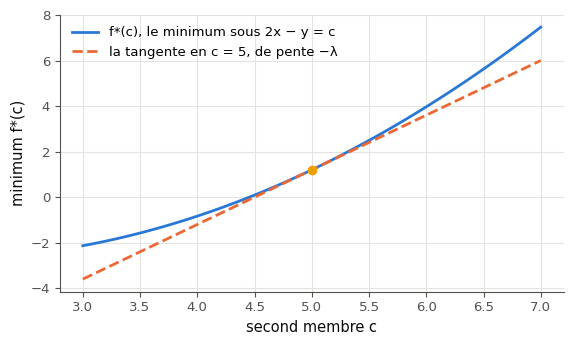

In [35]:
ref_29 = wbm.load_mymath("ref", alias="mymath_ref").svm


def solve_29(Q, lin, a, c):
    """(f*, λ) of min ½ xᵀQx + lin · x under a · x = c, with the reference lagrange_equality_qp."""
    x, lam = ref_29.lagrange_equality_qp(Q, lin, [a], [c])
    return float(0.5 * x @ Q @ x + lin @ x), float(lam[0])


f0_29, lam0_29 = solve_29(Q_29, LIN_29, A_29, RHS_29)
f1_29 = solve_29(Q_29, LIN_29, A_29, RHS_29 + 0.1)[0]
print(f"a) et b) f*(5) = {f0_29:.4f}, f*(5,1) = {f1_29:.4f} : le minimum change de {f1_29 - f0_29:+.4f}, "
      f"et −λ × 0,1 = {-lam0_29 * 0.1:+.4f}".replace(".", ","))
print(f"c) λ pour f : {lam0_29:.4f} ; pour 2f : {solve_29(2 * Q_29, 2 * LIN_29, A_29, RHS_29)[1]:.4f}".replace(".", ","))
print(f"d) λ pour 4x − 2y = 10 : {solve_29(Q_29, LIN_29, 2 * A_29, 2 * RHS_29)[1]:.4f}".replace(".", ","))
cs_29 = np.linspace(3.0, 7.0, 81)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(cs_29, [solve_29(Q_29, LIN_29, A_29, c)[0] for c in cs_29], label="f*(c), le minimum sous 2x − y = c")
ax.plot(cs_29, f0_29 - lam0_29 * (cs_29 - RHS_29), ls="--", label="la tangente en c = 5, de pente −λ")
ax.plot([RHS_29], [f0_29], "o", color="C3")
ax.set_xlabel("second membre c")
ax.set_ylabel("minimum f*(c)")
ax.legend()
plt.show()

**Après l'expérience**, dans ta copie : pourquoi l'écart mesuré en b) n'est-il pas exactement $-\lambda \times 0{,}1$ (regarde la courbure de $f^*(c)$) ? Écris la stationnarité pour $2f$ et pour la contrainte multipliée par 2, et retrouve c) et d) sans calcul. Que dit un multiplicateur nul ? Pourquoi le signe de $\lambda$ dépend-il de la convention $f + \lambda g$ ou $f - \lambda g$, et pas la variation de $f^*$ ?

💡 a) et b) La sensibilité $\frac{df^*}{dc} = -\lambda = 2{,}4$ (fiche §1) : le minimum monte d'environ $2{,}4 \times 0{,}1 = 0{,}24$ ; on mesure $0{,}2437$, parce que $f^*(c) = \frac{11}{30}c^2 - \frac{19}{15}c - \frac{49}{30}$ est une parabole, au-dessus de sa tangente. c) La stationnarité $2\nabla f + \lambda'\nabla g = \mathbf{0}$ et $\nabla f + \lambda\nabla g = \mathbf{0}$ donnent $\lambda' = 2\lambda = -4{,}8$ : un prix s'exprime dans l'unité de l'objectif. d) $\nabla f + \lambda'(2\nabla g) = \mathbf{0}$ donne $\lambda' = \lambda/2 = -1{,}2$ : une unité de la contrainte $4x - 2y = 10$ vaut une demi-unité de $2x - y = 5$. Le multiplicateur est un prix : il dépend de l'unité de l'objectif et de celle de la contrainte, pas du point solution, qui ne change dans aucun des deux cas.

### Ex M13b.30 — La descente de sous-gradient sur la hinge loss : pas constant contre pas décroissant 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer comment le choix du pas règle la descente de sous-gradient sur l'objectif d'une SVM linéaire : oscillations d'un pas constant, lenteur d'un petit pas, convergence d'un pas décroissant.  
**Prérequis :** fiche §7 · **Parcours :** C

150 exemples synthétiques en dimension 3, de deux classes qui se chevauchent un peu (cellule fournie), et l'objectif $J(\mathbf{w}, b)$ d'une SVM à marge souple avec $C = 0{,}5$. La cellule fournie calcule aussi son minimum $J^*$, avec la SVM de scikit-learn (`SVC(kernel="linear", C=0.5, tol=1e-10)`, un solveur du dual) et la fonction `svm_subgradient` de la référence, `ref_30`. Écris :
- `run_subgradient(X, y, C, steps, eta)` : la descente de sous-gradient qui part de $\mathbf{w} = \mathbf{0}$, $b = 0$ et, pour $t = 1, \ldots,$ `steps`, calcule `(J, g_w, g_b) = svm_subgradient(w, b, X, y, C)` (celle de la référence, `ref_30.svm_subgradient`, ou la tienne), range $J$ dans une liste, puis fait le pas $(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - \eta_t\,(\mathbf{g}_{\mathbf{w}}, g_b)$, avec $\eta_t$ = `eta(t)`. Elle rend la liste des `steps` valeurs de $J$, la première étant $J(\mathbf{0}, 0)$.

Lance-la pour les trois réglages du dictionnaire `SCHEDULES_30` (un pas constant 0,01, un pas constant 0,001, un pas décroissant $\eta_t = 0{,}01/\sqrt{t}$), avec 300 itérations, puis calcule :
- a) les trois meilleurs écarts $\min_t J_t - J^*$, dans l'ordre de `SCHEDULES_30` (une liste, 6 décimales) ;
- b) vrai ou faux : le pas décroissant finit avec un meilleur écart plus petit que celui des deux pas constants ;
- c) le nombre d'itérations où $J$ **remonte** ($J_{t+1} > J_t$) avec le pas constant 0,01 (un entier).

Une cellule trace ensuite $J_t - J^*$ en échelle logarithmique pour les trois réglages, avec le meilleur écart vu.

Dans ta copie : pourquoi le pas constant 0,01 ne descend-il plus sous un certain niveau, et pourquoi $J$ remonte-t-il si souvent (la fiche §7 dit pourquoi ce n'est pas une méthode de descente) ? Pourquoi le pas constant 0,001 est-il si lent au début ? Que garde le pas décroissant de chacun des deux ? Pourquoi garde-t-on le **meilleur** point vu, et pas le dernier ?

In [36]:
from sklearn.svm import SVC

rng_30 = np.random.default_rng(4230)
Y_30 = np.where(rng_30.random(150) < 0.5, -1, 1)                                     # 150 labels ±1
X_30 = rng_30.normal(0.0, 1.0, size=(150, 3)) + np.outer(Y_30, [0.9, -0.7, 0.5])    # two classes that overlap a bit
C_30, STEPS_30 = 0.5, 300
SCHEDULES_30 = {"constant 0,01": lambda t: 0.01,                                     # the step η_t at iteration t
                "constant 0,001": lambda t: 0.001,
                "décroissant 0,01/√t": lambda t: 0.01 / math.sqrt(t)}
ref_30 = wbm.load_mymath("ref", alias="mymath_ref").svm
svc_30 = SVC(kernel="linear", C=C_30, tol=1e-10).fit(X_30, Y_30)
J_STAR_30 = ref_30.svm_subgradient(svc_30.coef_[0], float(svc_30.intercept_[0]), X_30, Y_30, C_30)[0]   # min of J

J* = 21.678929  ; a) [0.000733, 0.000133, 8.2e-05]  b) True  c) 129
       constant 0,01 : meilleur écart après 10, 50, 100, 300 itérations : ['1.1e-01', '2.3e-03', '2.2e-03', '7.3e-04']  ; dernier écart : 3.3e-02  ; remontées : 129
      constant 0,001 : meilleur écart après 10, 50, 100, 300 itérations : ['8.9e+00', '1.0e+00', '1.6e-01', '1.3e-04']  ; dernier écart : 6.3e-04  ; remontées : 58
 décroissant 0,01/√t : meilleur écart après 10, 50, 100, 300 itérations : ['5.4e-01', '3.1e-02', '5.7e-04', '8.2e-05']  ; dernier écart : 1.3e-04  ; remontées : 103


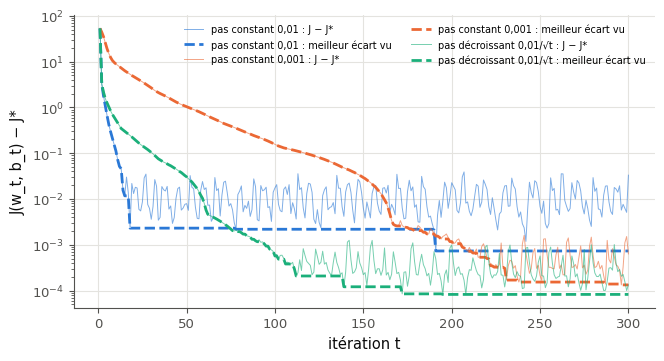

In [37]:
def run_subgradient(X, y, C, steps, eta):
    """The list of the `steps` values J(w_t, b_t) of the subgradient descent that starts at w = 0, b = 0 and, for
    t = 1, ..., steps, computes (J, g_w, g_b) = svm_subgradient(w, b, X, y, C) (ref_30.svm_subgradient, or your
    own), stores J, then steps (w, b) <- (w, b) - eta(t) * (g_w, g_b)."""
    w, b, values = np.zeros(np.shape(X)[1]), 0.0, []
    for t in range(1, steps + 1):
        J, g_w, g_b = ref_30.svm_subgradient(w, b, X, y, C)
        values.append(J)
        w, b = w - eta(t) * g_w, b - eta(t) * g_b
    return values


runs_30 = {name: np.array(run_subgradient(X_30, Y_30, C_30, STEPS_30, eta)) for name, eta in SCHEDULES_30.items()}
gaps_30 = [float(run.min() - J_STAR_30) for run in runs_30.values()]
answer_M13b_30a = [round(g, 6) for g in gaps_30]
answer_M13b_30b = gaps_30[2] < min(gaps_30[:2])
answer_M13b_30c = int(np.sum(np.diff(runs_30["constant 0,01"]) > 0))
print("J* =", round(J_STAR_30, 6), " ; a)", answer_M13b_30a, " b)", answer_M13b_30b, " c)", answer_M13b_30c)
for name, run in runs_30.items():
    best = np.minimum.accumulate(run) - J_STAR_30
    print(f"{name:>20} : meilleur écart après 10, 50, 100, 300 itérations :",
          [f"{best[t - 1]:.1e}" for t in (10, 50, 100, 300)], " ; dernier écart :", f"{run[-1] - J_STAR_30:.1e}",
          " ; remontées :", int(np.sum(np.diff(run) > 0)))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
try:
    for (name, eta), color in zip(SCHEDULES_30.items(), ("C0", "C1", "C2")):
        gaps = np.asarray(run_subgradient(X_30, Y_30, C_30, STEPS_30, eta), dtype=float) - J_STAR_30
        steps = np.arange(1, len(gaps) + 1)
        ax.semilogy(steps, np.maximum(gaps, 1e-9), color=color, lw=0.7, alpha=0.6, label=f"pas {name} : J − J*")
        ax.semilogy(steps, np.maximum(np.minimum.accumulate(gaps), 1e-9), color=color, lw=2, ls="--",
                    label=f"pas {name} : meilleur écart vu")
    ax.set_xlabel("itération t")
    ax.set_ylabel("J(w_t, b_t) − J*")
    ax.legend(fontsize=7, ncol=2)
except BaseException:
    plt.close(fig)
    raise
plt.show()

In [38]:
from sklearn.svm import SVC as SVC_r

rng_30r = np.random.default_rng(4230)
y_30r = np.where(rng_30r.random(150) < 0.5, -1, 1)
x_30r = rng_30r.normal(0.0, 1.0, size=(150, 3)) + np.outer(y_30r, [0.9, -0.7, 0.5])


def j_30r(w, b):
    """J(w, b), computed directly."""
    return 0.5 * float(w @ w) + 0.5 * float(np.sum(np.maximum(0.0, 1.0 - y_30r * (x_30r @ w + b))))


def descent_30r(eta):
    """The 300 values J(w_t, b_t) of the descent, computed without svm_subgradient."""
    w, b, values = np.zeros(3), 0.0, []
    for t in range(1, 301):
        below = y_30r * (x_30r @ w + b) < 1
        values.append(j_30r(w, b))
        g_w, g_b = w - 0.5 * (y_30r[below] @ x_30r[below]), -0.5 * float(np.sum(y_30r[below]))
        w, b = w - eta(t) * g_w, b - eta(t) * g_b
    return np.array(values)


svc_30r = SVC_r(kernel="linear", C=0.5, tol=1e-10).fit(x_30r, y_30r)
star_30r = j_30r(svc_30r.coef_[0], float(svc_30r.intercept_[0]))
runs_30r = [descent_30r(eta) for eta in (lambda t: 0.01, lambda t: 0.001, lambda t: 0.01 / math.sqrt(t))]
best_30r = [float(run.min() - star_30r) for run in runs_30r]
wbm.record("M13b.30a", best_30r, decimals=6,
           mistakes={"le MEILLEUR écart, min_t J_t − J*, pas le dernier": [float(run[-1] - star_30r) for run in runs_30r],
                     "l'écart à J* : retranche J_STAR_30": [float(run.min()) for run in runs_30r]})
wbm.record("M13b.30b", best_30r[2] < min(best_30r[:2]),
           mistakes={"compare le meilleur écart du pas décroissant au plus petit des deux autres": False})
ups_30r = int(np.sum(np.diff(runs_30r[0]) > 0))
wbm.record("M13b.30c", ups_30r,
           mistakes={"compte les t où J remonte, J_(t+1) > J_t, pas ceux où il baisse": len(runs_30r[0]) - 1 - ups_30r})

WBM_ANSWER {"array_rounded": {"1": "fab4b30090b9522869b28a4ec4da82390092a14c1d3d9d09bc5923031a8b0baf", "2": "fab4b30090b9522869b28a4ec4da82390092a14c1d3d9d09bc5923031a8b0baf", "3": "df71407eed890c11b358c25574e9bfcaaee55cb3deaa2676c90f5a98c5707645", "4": "4bbab0e304f012f0f4608327c18e1110cb625ed4035dcb9cf16b88601a18714f", "5": "f7feea2162a9cc08d0ccc8706a2103d16fa9b6d68a321de4db796375cde1210e"}, "decimals": 6, "element_coarse": [["6632f29aad0ab8ad22abaf666be70f9071bdc27db25719194ac7b588aff28cc3"], ["f9483723a817e7503005f555b8e5956b39635bc9637aa3497cabf4d0551633d0"], ["80ec01b5b07c8c41da39edca739d6385986e5e4ce3a1fcdd477e62cb9109820c"]], "element_coarse_any": [["2f479d9259f3b6ad66bc69924827296a7fdf904ae5ecd2ba3c5d82813d32b4af", "c4bd26d71671b68906af59ec53b7423a97323c9438300a17cb3e2df2fb1a8d83"], ["fac18e015e3e2968a7227862742d5bb7beb7f95dab6ce91ed87e9dc89f848147"], ["223065358abe331ff61166280ba98f47a804917cbdd0055cda3b9b0759c7c45e"]], "element_hashes": ["e293e11feb16733f7ae54d9b9a579c4c6a1fd

💡 Meilleurs écarts après 300 itérations : $\approx 7{,}3 \times 10^{-4}$ (pas 0,01), $1{,}3 \times 10^{-4}$ (pas 0,001) et $8{,}2 \times 10^{-5}$ (pas décroissant), pour $J^* \approx 21{,}68$. Le pas 0,01 descend vite, puis oscille : son meilleur écart reste à $7{,}3 \times 10^{-4}$ dès la 200ᵉ itération, son dernier écart vaut $\approx 0{,}033$, et $J$ remonte 129 fois sur 299 pas. Le pas 0,001 oscille moins, mais démarre lentement (écart $\approx 1$ après 50 itérations). Le pas $0{,}01/\sqrt{t}$ fait les grands pas du premier au début et des pas de plus en plus fins ensuite : il atteint $8{,}2 \times 10^{-5}$ dès la 200ᵉ itération. Un pas de sous-gradient ne garantit pas la baisse (fiche §7) : on garde le meilleur point vu. Sur un autre dataset, l'ordre des deux pas constants peut changer ; la théorie ne garantit la convergence qu'au pas décroissant.

### Ex M13b.31 — Lignes de niveau et contrainte : voir le point de Lagrange 🎨 ★ ⏱️ 20 min
**Objectif :** trouver numériquement le minimum d'une fonction sur une courbe, et voir qu'en ce point la ligne de niveau touche la courbe et que les deux gradients sont colinéaires.  
**Prérequis :** fiche §1 · **Parcours :** C, E

On minimise $f(x, y) = (x - 3)^2 + 2(y + 1)^2$, dont les lignes de niveau sont des ellipses centrées en $(3, -1)$, sous la contrainte $g(x, y) = \frac{x^2}{2} - 2 - y = 0$ : le point doit rester sur la parabole $y = \frac{x^2}{2} - 2$. La cellule fournie donne $f$, $g$ et leurs gradients. Écris `draw_lagrange(ax)`, qui, dans l'axe reçu (sans en ouvrir d'autre) :
- trouve le point de Lagrange **par ta propre méthode numérique** : par exemple, paramètre la parabole par $x$ (le point $(x, \frac{x^2}{2} - 2)$), calcule $f$ sur une grille fine de valeurs de $x$ (`np.linspace`, des dizaines de milliers de points) et garde la plus petite ;
- trace quelques lignes de niveau de $f$ (`ax.contour` sur une grille `np.meshgrid`), dont celle qui passe par ce point, la parabole, et le point ;
- dessine en ce point les deux gradients $\nabla f$ et $\nabla g$, ramenés à la même longueur (`ax.annotate` avec une flèche, ou `ax.quiver`) ;
- met `ax.set_aspect("equal")`, une légende et un titre ;
- **rend** le point trouvé, le couple `(x, y)`.

La cellule de vérification appelle ta fonction, contrôle que le point est sur la parabole (à $10^{-3}$ près) et que les deux gradients y sont colinéaires (le sinus de leur angle sous 0,01), puis affiche ta figure.

Dans ta copie : écris le système de Lagrange de ce problème, élimine $y$ et $\lambda$, et montre que $x$ vérifie $x^3 - x - 3 = 0$. Pourquoi cette équation n'a-t-elle qu'une racine réelle (regarde les variations de $x^3 - x - 3$), et que vaut $\lambda$ ? Sur ta figure, la ligne de niveau du point traverse-t-elle la parabole, ou la touche-t-elle ? Que se passerait-il en un point de la parabole où les gradients ne sont pas colinéaires ?

In [39]:
def f_31(x, y):
    """The objective (x − 3)² + 2(y + 1)²: its level lines are ellipses centred at (3, −1)."""
    return (x - 3) ** 2 + 2 * (y + 1) ** 2


def grad_f_31(x, y):
    """The gradient of f_31 at (x, y)."""
    return np.array([2 * (x - 3), 4 * (y + 1)], dtype=float)


def g_31(x, y):
    """The constraint g = 0: the parabola y = x²/2 − 2."""
    return x ** 2 / 2 - 2 - y


def grad_g_31(x, y):
    """The gradient of g_31 at (x, y)."""
    return np.array([x, -1.0], dtype=float)

point (1,6717 ; -0,6027), λ = 1,5892, x³ − x − 3 = 8,7e-07
✅ draw_lagrange dessine dans l'axe reçu
✅ le point (1,6717 ; -0,6027) est sur la contrainte
✅ ∇f et ∇g sont colinéaires en ce point (sinus de leur angle : 2,9e-07)


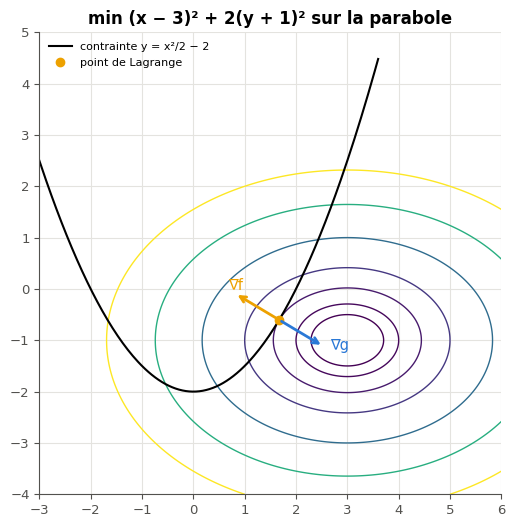

✅ Ex M13b.31 : le point de Lagrange est juste, et la figure est dans l'axe reçu.


In [40]:
def draw_lagrange(ax):
    """In the axes received (and no other): the level lines of f_31, the parabola g_31 = 0, the Lagrange point found
    numerically (the minimum of f_31 on the parabola), and the two gradients at that point. Return the point (x, y)."""
    xs = np.linspace(-4.0, 4.0, 160001)               # the parabola, parametrized by x: a step of 5e-5
    best = int(np.argmin(f_31(xs, xs ** 2 / 2 - 2)))
    x_star = float(xs[best])
    y_star = x_star ** 2 / 2 - 2
    gx, gy = np.meshgrid(np.linspace(-3.0, 6.0, 300), np.linspace(-4.0, 5.0, 300))
    levels = sorted({0.5, 1.0, round(f_31(x_star, y_star), 4), 4.0, 8.0, 14.0, 22.0})
    ax.contour(gx, gy, f_31(gx, gy), levels=levels, cmap="viridis", linewidths=1)
    curve = np.linspace(-3.0, 3.6, 200)
    ax.plot(curve, curve ** 2 / 2 - 2, color="black", lw=1.5, label="contrainte y = x²/2 − 2")
    ax.plot(x_star, y_star, "o", color="C3", label="point de Lagrange")
    for grad, color, name in ((grad_f_31(x_star, y_star), "C3", "∇f"), (grad_g_31(x_star, y_star), "C0", "∇g")):
        u = grad / np.linalg.norm(grad)
        ax.annotate("", xy=(x_star + u[0], y_star + u[1]), xytext=(x_star, y_star),
                    arrowprops=dict(arrowstyle="->", color=color, lw=2))
        ax.text(x_star + 1.15 * u[0], y_star + 1.15 * u[1], name, color=color)
    ax.set_xlim(-3.0, 6.0)
    ax.set_ylim(-4.0, 5.0)
    ax.set_aspect("equal")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_title("min (x − 3)² + 2(y + 1)² sur la parabole")
    return x_star, y_star


x_31, y_31 = draw_lagrange(plt.figure().add_subplot())
plt.close()
lam_31 = -grad_f_31(x_31, y_31)[0] / grad_g_31(x_31, y_31)[0]
print(f"point ({x_31:.4f} ; {y_31:.4f}), λ = {lam_31:.4f}, x³ − x − 3 = {x_31 ** 3 - x_31 - 3:.1e}".replace(".", ","))


with checked("M13b.31"):
    results_31 = []

    def report_31(ok, success, failure):
        results_31.append(bool(ok))
        print(("✅ " + success) if ok else ("❌ " + failure))

    fig, ax = plt.subplots(figsize=(6.5, 6.0))
    try:
        returned_31 = []
        opened_31 = drawn(lambda axis: returned_31.append(draw_lagrange(axis)), ax)
    except BaseException:
        plt.close(fig)
        raise
    report_31(not opened_31 and bool(ax.lines or ax.collections), "draw_lagrange dessine dans l'axe reçu",
              "draw_lagrange doit dessiner dans l'axe reçu, sans ouvrir de figure (ni plt.figure ni plt.subplots)")
    try:
        x_31, y_31 = (float(v) for v in returned_31[0])
        point_ok_31 = math.isfinite(x_31) and math.isfinite(y_31)
    except (TypeError, ValueError, IndexError):
        point_ok_31 = False
    if not point_ok_31:
        report_31(False, "", "draw_lagrange doit rendre le point trouvé, un couple de deux nombres (x, y)")
    else:
        gap_31 = abs(g_31(x_31, y_31))
        report_31(gap_31 <= 1e-3, f"le point ({fr(x_31, 4)} ; {fr(y_31, 4)}) est sur la contrainte",
                  f"le point ({fr(x_31, 4)} ; {fr(y_31, 4)}) n'est pas sur la parabole : |g| = {fr(gap_31, 4)} > 0,001")
        gf_31, gg_31 = grad_f_31(x_31, y_31), grad_g_31(x_31, y_31)
        sine_31 = abs(gf_31[0] * gg_31[1] - gf_31[1] * gg_31[0]) / (np.linalg.norm(gf_31) * np.linalg.norm(gg_31) or 1.0)
        report_31(sine_31 < 1e-2, f"∇f et ∇g sont colinéaires en ce point (sinus de leur angle : {sine_31:.1e})".replace(".", ","),
                  f"∇f et ∇g ne sont pas colinéaires en ce point : le sinus de leur angle vaut {fr(sine_31, 4)}, plus "
                  "que 0,01 ; cherche le minimum de f sur la courbe plus finement")
    plt.show()
    verdict("M13b.31", all(results_31), "le point de Lagrange est juste, et la figure est dans l'axe reçu.",
            "relis les lignes ❌ ci-dessus.")

💡 La stationnarité $2(x - 3) + \lambda x = 0$, $4(y + 1) - \lambda = 0$, avec $y = \frac{x^2}{2} - 2$, donne $\lambda = 4(y + 1) = 2x^2 - 4$ puis $2x - 6 + 2x^3 - 4x = 0$, soit $x^3 - x - 3 = 0$. Sa dérivée $3x^2 - 1$ s'annule en $\pm\frac{1}{\sqrt{3}}$, où la fonction vaut $\approx -3{,}4$ et $\approx -2{,}6$, deux valeurs négatives : une seule racine réelle, $x^* \approx 1{,}6717$, donc $y^* \approx -0{,}6027$ et $\lambda \approx 1{,}589$. Sur la figure, l'ellipse $f = f^* \approx 2{,}08$ touche la parabole sans la traverser, et les deux gradients sont portés par la même droite, de sens opposés ($\nabla f = -\lambda\nabla g$). En un point où ils ne sont pas colinéaires, $\nabla f$ a une composante le long de la courbe : en glissant sur la parabole dans le sens opposé, $f$ baisse, et le point n'est pas le minimum.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §3, §6, §7 et §8. Quatre erreurs à trouver dans un résumé de SVM, une fonction qui vérifie les conditions KKT, puis une SVM linéaire entraînée par sous-gradient jusqu'à un objectif chiffré.

### Ex M13b.32 — Chasse à l'erreur : le signe d'un multiplicateur, une largeur de bande 1/‖w‖ au lieu de 2/‖w‖, une matrice de Gram non symétrique 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans un résumé de SVM les erreurs classiques des multiplicateurs, de la marge et des noyaux, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §3, §6 et §8 · **Parcours :** C

Un collègue résume une SVM linéaire et une vérification de conditions KKT (la cellule fournie) : six exemples `X_32` et leurs labels, quatre autres points `Z_32`, un séparateur $(\mathbf{w}, b)$, le poids $C$ et un paramètre $\gamma$ ; puis un candidat `P_32` pour un petit problème à une contrainte d'inégalité, avec le multiplicateur `MU_32` qui y rend la stationnarité vraie. Sept lignes portent une lettre et un commentaire qui dit ce qu'elles doivent calculer. Quatre lignes ne font pas ce que dit leur commentaire. **Sans exécuter son code**, trouve-les.

```python
X, y, w, b = X_32, Y_32, W_32, B_32
margins = y * (X @ w + b)                                            # (A) the functional margins t_i
J = 0.5 * w @ w + C_32 * np.mean(np.maximum(0, 1 - margins))         # (B) the soft-margin objective J(w, b)
band = 1 / np.linalg.norm(w)                                         # (C) the width of the band
rho = 1 / np.linalg.norm(w)                                          # (D) the margin ρ, from the boundary to a border
K = np.exp(-GAMMA_32 * np.sum((X[:, None, :] - X[None, :, :]) ** 2, axis=2))   # (E) the RBF Gram matrix of X
G = X @ Z_32.T                                                       # (F) the linear Gram matrix of X, x_i · x_j
kkt = STATIONARY_32 and G_P_32 <= 1e-12 and abs(MU_32 * G_P_32) <= 1e-12   # (G) (P_32, MU_32) is a KKT point
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) la bonne valeur de `J` (4 décimales) ;
- c) la bonne valeur de `band` (4 décimales) ;
- d) la somme de tous les coefficients de la bonne matrice `G` (4 décimales) ;
- e) la bonne valeur de `kkt` (`True` ou `False`).

Pour b) à e), écris le code corrigé dans la cellule (c'est permis : seule la recherche des lignes fausses se fait sans exécuter).

In [41]:
X_32 = np.array([[1.5, -0.5], [0.0, 2.5], [-1.0, 1.0], [2.5, 1.5], [-2.0, -1.5], [0.5, 3.0]])   # 6 examples
Y_32 = np.array([1, -1, -1, 1, -1, 1])                                                    # their labels
Z_32 = np.array([[1.0, 0.5], [-0.5, 2.0], [3.0, -1.5], [0.0, -2.5]])                      # 4 new points
W_32, B_32, C_32, GAMMA_32 = np.array([1.2, -0.5]), 0.1, 2.0, 0.5
# A candidate for min (p₁ − 3)² + (p₂ − 0.5)² under g(p) = p₁ + 2p₂ − 6 ≤ 0: the point P_32 of the line g = 0, and
# the μ that makes the stationarity ∇f + μ∇g = 0 hold there
P_32 = np.array([3.4, 1.3])
GRAD_F_32, GRAD_G_32 = 2 * (P_32 - np.array([3.0, 0.5])), np.array([1.0, 2.0])
G_P_32 = float(P_32 @ GRAD_G_32 - 6)                                                     # g(P_32)
MU_32 = float(-(GRAD_F_32 @ GRAD_G_32) / (GRAD_G_32 @ GRAD_G_32))
STATIONARY_32 = bool(np.allclose(GRAD_F_32 + MU_32 * GRAD_G_32, 0.0))

In [42]:
answer_M13b_32a = "BCFG"
margins_32 = Y_32 * (X_32 @ W_32 + B_32)                                    # (A) right
J_32 = 0.5 * W_32 @ W_32 + C_32 * np.sum(np.maximum(0, 1 - margins_32))    # (B) C times the SUM of the hinges
band_32 = 2 / np.linalg.norm(W_32)                                          # (C) the band is 2ρ wide
G_32 = X_32 @ X_32.T                                                        # (F) n × n, symmetric
kkt_32 = STATIONARY_32 and G_P_32 <= 1e-12 and abs(MU_32 * G_P_32) <= 1e-12 and MU_32 >= 0   # (G) the sign of μ too
answer_M13b_32b, answer_M13b_32c = round(float(J_32), 4), round(float(band_32), 4)
answer_M13b_32d, answer_M13b_32e = round(float(G_32.sum()), 4), bool(kkt_32)
print(answer_M13b_32a, answer_M13b_32b, answer_M13b_32c, answer_M13b_32d, answer_M13b_32e)
print("lignes du collègue : (B)", round(float(0.5 * W_32 @ W_32 + C_32 * np.mean(np.maximum(0, 1 - margins_32))), 4),
      " (C)", round(float(1 / np.linalg.norm(W_32)), 4), " (F) forme", (X_32 @ Z_32.T).shape,
      " (G)", STATIONARY_32 and G_P_32 <= 1e-12 and abs(MU_32 * G_P_32) <= 1e-12, " ; MU_32 =", round(MU_32, 4))
print("marges :", np.round(margins_32, 2).tolist(), " ; g au minimum libre (3 ; 0,5) :", 3.0 + 2 * 0.5 - 6)

BCFG 4.445 1.5385 38.25 False
lignes du collègue : (B) 1.445  (C) 0.7692  (F) forme (6, 4)  (G) True  ; MU_32 = -0.8
marges : [2.15, 1.15, 1.6, 2.35, 1.55, -0.8]  ; g au minimum libre (3 ; 0,5) : -2.0


In [43]:
wbm.record("M13b.32a", "BCFG",
           mistakes={"il manque une ligne fautive : regarde comment C pèse les hinges dans l'objectif J": "CFG",
                     "il manque une ligne fautive : compare la largeur de la bande et la marge ρ": "BFG",
                     "il manque une ligne fautive : regarde la forme et la symétrie de la matrice que la ligne calcule": "BCG",
                     "il manque une ligne fautive : relis les quatre conditions KKT : sont-elles toutes testées ?": "BCF",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCFG", "BCDFG", "BCEFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde comment C pèse les hinges dans l'objectif J": {"ACFG", "CDFG", "CEFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : compare la largeur de la bande et la marge ρ": {"ABFG", "BDFG", "BEFG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : regarde la forme et la symétrie de la matrice que la ligne calcule": {"ABCG", "BCDG", "BCEG"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis les quatre conditions KKT : sont-elles toutes testées ?": {"ABCF", "BCDF", "BCEF"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"A", "D", "E", "AB", "AC", "AD", "AE", "AF", "AG", "BD", "BE", "CD", "CE", "DE", "DF", "DG", "EF", "EG", "ABC", "ABD", "ABE", "ABF", "ABG", "ACD", "ACE", "ACF", "ACG", "ADE", "ADF", "ADG", "AEF", "AEG", "AFG", "BCD", "BCE", "BDE", "BDF", "BDG", "BEF", "BEG", "CDE", "CDF", "CDG", "CEF", "CEG", "DEF", "DEG", "DFG", "EFG", "ABCD", "ABCE", "ABDE", "ABDF", "ABDG", "ABEF", "ABEG", "ACDE", "ACDF", "ACDG", "ACEF", "ACEG", "ADEF", "ADEG", "ADFG", "AEFG", "BCDE", "BDEF", "BDEG", "CDEF", "CDEG", "DEFG", "ABCDE", "ABCDF", "ABCDG", "ABCEF", "ABCEG", "ABDEF", "ABDEG", "ABDFG", "ABEFG", "ACDEF", "ACDEG", "ACDFG", "ACEFG", "ADEFG", "BCDEF", "BCDEG", "BDEFG", "CDEFG", "ABCDEF", "ABCDEG", "ABDEFG", "ACDEFG"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"B", "C", "F", "G", "BC", "BF", "BG", "CF", "CG", "FG"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDFG", "ABCEFG", "BCDEFG", "ABCDEFG"}})
x_32r, y_32r = np.array([[1.5, -0.5], [0.0, 2.5], [-1.0, 1.0], [2.5, 1.5], [-2.0, -1.5], [0.5, 3.0]]), \
    np.array([1, -1, -1, 1, -1, 1])
z_32r, w_32r, b_32r, c_32r = np.array([[1.0, 0.5], [-0.5, 2.0], [3.0, -1.5], [0.0, -2.5]]), np.array([1.2, -0.5]), 0.1, 2.0
hinges_32r = np.maximum(0.0, 1.0 - y_32r * (x_32r @ w_32r + b_32r))
norm_32r = float(np.hypot(*w_32r))
wbm.record("M13b.32b", 0.5 * float(w_32r @ w_32r) + c_32r * float(hinges_32r.sum()), decimals=4,
           mistakes={"C multiplie la SOMME des hinges dans J, pas leur moyenne": 0.5 * float(w_32r @ w_32r) + c_32r * float(hinges_32r.mean())})
wbm.record("M13b.32c", 2 / norm_32r, decimals=4,
           mistakes={"la bande s'étend des deux côtés de la frontière : sa largeur est 2ρ = 2/‖w‖": 1 / norm_32r,
                     "la largeur de la bande est 2/‖w‖, avec la norme de w": 2 / float(w_32r @ w_32r)})
wbm.record("M13b.32d", float(sum(float(xi @ xj) for xi in x_32r for xj in x_32r)), decimals=4,
           mistakes={"la matrice de Gram des exemples est X Xᵀ, de taille n × n : la somme de ses coefficients":
                         float((x_32r @ z_32r.T).sum())})
wbm.record("M13b.32e", False,
           mistakes={"un multiplicateur d'inégalité doit être positif ou nul : regarde le signe de MU_32": True})

WBM_ANSWER {"hash": "e8428f0e2006274a28dd64d8fee36e6a7613dbde30c8221ae927cf254c875110", "id": "M13b.32a", "kind": "str", "mistakes": {"03bcd5526c9966545fe8fb93846cfc982dcd4bf7b44cfc141473bad34186eb72": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0911bb75e32ea21510510f6e856b2a962505b98cdbc2931827a35446e75a8313": "une des lignes que tu cites est correcte, et il manque une ligne fautive : relis les quatre conditions KKT : sont-elles toutes testées ?", "0ab27748d1cda3311c74ad5f51c89937bd1b0c68807aa94231f6f8a0c1a126b1": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0cdf1c8247149a432136af3d5c7f6ed34391233346146915b9691418f97bfe02": "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple", "104cdbdf5823738d835508d3d39efd1878fdf3af1fc1b2c890cbf47f6ecefc77": "il manque des lignes fautives, et des lignes que tu cites

**Après la vérification**, dans ta copie : pour chaque ligne fausse, que calcule-t-elle exactement, et comment la corriger ? Laquelle donne une matrice de la mauvaise forme, et laquelle un nombre plausible sans aucun signal ? Pourquoi les lignes (C) et (D), presque identiques, ne sont-elles pas toutes les deux fausses ? Pour (G), que dit le signe de `MU_32` sur la contrainte, et quel est le vrai minimum de ce petit problème ?

💡 (B) $C$ multiplie la **somme** des hinges : la moyenne divise le terme d'attache aux données par $n = 6$ (le collègue trouve $\approx 1{,}4450$ au lieu de $4{,}4450$), un nombre plausible sans aucun signal. (C) La bande a une largeur $2\rho = 2/\lVert\mathbf{w}\rVert = 2/1{,}3 \approx 1{,}5385$ ; (D), presque la même ligne, calcule la marge $\rho$ : elle est juste. (F) `X @ Z_32.T` est la matrice $6 \times 4$ des produits scalaires des exemples avec d'autres points ; la matrice de Gram des exemples est $\mathbf{X}\mathbf{X}^\top$, $6 \times 6$ et symétrique, dont la somme des coefficients vaut $\lVert\sum_i \mathbf{x}_i\rVert^2 = 1{,}5^2 + 6^2 = 38{,}25$. (E) élève bien les distances au carré : elle est juste. (G) oublie la condition de signe : `MU_32` $= -0{,}8 < 0$ dit que la contrainte supposée active ne devrait pas l'être. Le minimum libre $(3 ;\ 0{,}5)$ vérifie $g = -2 < 0$ : c'est la solution, avec $\mu = 0$ (fiche §3).

### Ex M13b.33 — Vérifier une solution KKT : faisabilité, stationnarité, complémentarité 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire une fonction qui vérifie les quatre conditions KKT d'une solution candidate, pour n'importe quel problème à contraintes d'inégalité.  
**Prérequis :** fiche §3 · **Parcours :** C

Un solveur, un collègue ou toi-même proposez une solution $(\mathbf{x}, \boldsymbol{\mu})$ d'un problème $\min f(\mathbf{x})$ sous $g_i(\mathbf{x}) \le 0$ : avant de la croire, on la **vérifie** (le réflexe de la fiche). Écris `check_kkt(grad_f, constraints, x, mu, tol=1e-8)`, pour un problème quelconque : `grad_f` est une fonction qui rend $\nabla f(\mathbf{x})$, `constraints` une liste de couples `(g_i, grad_g_i)` de fonctions, `x` le point et `mu` les multiplicateurs, un par contrainte. Elle rend le dictionnaire des quatre conditions de la fiche §3, chacune `True` ou `False` :
- `"feasibility"` : chaque $g_i(\mathbf{x}) \le$ `tol` ;
- `"stationarity"` : chaque coordonnée de $\nabla f(\mathbf{x}) + \sum_i \mu_i\nabla g_i(\mathbf{x})$ est, en valeur absolue, au plus `tol` ;
- `"sign"` : chaque $\mu_i \ge -$`tol` ;
- `"complementarity"` : chaque $\lvert\mu_i\,g_i(\mathbf{x})\rvert \le$ `tol`.

La cellule fournie définit un problème : $f(\mathbf{x}) = (x_1 - 1)^2 + 3(x_2 - 4)^2$, sous $g_1(\mathbf{x}) = -x_1 + 3x_2 - 3 \le 0$ et $g_2(\mathbf{x}) = x_1 - x_2 - 5 \le 0$. La cellule de vérification essaie ta fonction sur cinq candidats : un point KKT, un point hors de l'ensemble admissible, un multiplicateur négatif, une complémentarité violée et un gradient du lagrangien non nul, et dit ✅ ou ❌ pour chacun.

Dans ta copie : vérifie à la main le premier candidat, $\mathbf{x} = (3, 2)$ et $\boldsymbol{\mu} = (4, 0)$. Pourquoi ce point est-il **le** minimum, et pas seulement un point KKT (fiche §5) ? Le troisième candidat, $(7, 2)$ avec $\boldsymbol{\mu} = (0, -12)$, vérifie trois conditions sur quatre : que dit son multiplicateur négatif ? Pourquoi faut-il une tolérance, et que se passerait-il avec `tol=0` pour un point calculé en flottants ?

In [44]:
def grad_f_33(x):
    """The gradient of f(x) = (x₁ − 1)² + 3(x₂ − 4)²."""
    return np.array([2 * (x[0] - 1), 6 * (x[1] - 4)], dtype=float)


CONSTRAINTS_33 = [                                                       # (g_i, its gradient): g_i(x) ≤ 0
    (lambda x: -x[0] + 3 * x[1] - 3, lambda x: np.array([-1.0, 3.0])),   # g₁(x) = −x₁ + 3x₂ − 3
    (lambda x: x[0] - x[1] - 5, lambda x: np.array([1.0, -1.0])),        # g₂(x) = x₁ − x₂ − 5
]

In [45]:
def check_kkt(grad_f, constraints, x, mu, tol=1e-8):
    """The four KKT conditions at (x, mu) for min f(x) under g_i(x) <= 0: a dict {"feasibility", "stationarity",
    "sign", "complementarity"} of booleans; constraints is a list of pairs (g_i, grad_g_i), one per multiplier."""
    x, mu = np.asarray(x, dtype=float), np.asarray(mu, dtype=float)
    g = np.array([float(g_i(x)) for g_i, _ in constraints])
    rest = np.asarray(grad_f(x), dtype=float) + sum(m * np.asarray(dg(x), dtype=float)
                                                    for m, (_, dg) in zip(mu, constraints))
    return {"feasibility": bool(np.all(g <= tol)), "stationarity": bool(np.max(np.abs(rest)) <= tol),
            "sign": bool(np.all(mu >= -tol)), "complementarity": bool(np.all(np.abs(mu * g) <= tol))}


print("g(3, 2) =", [g_i(np.array([3.0, 2.0])) for g_i, _ in CONSTRAINTS_33], " ; ∇f(3, 2) =",
      grad_f_33(np.array([3.0, 2.0])).tolist())


with checked("M13b.33"):
    KEYS_33 = ("feasibility", "stationarity", "sign", "complementarity")
    CASES_33 = [("un point KKT", [3.0, 2.0], [4.0, 0.0]),
                ("le minimum libre, hors de l'ensemble admissible", [1.0, 4.0], [0.0, 0.0]),
                ("un multiplicateur négatif", [7.0, 2.0], [0.0, -12.0]),
                ("une complémentarité violée", [3.5, 1.5], [5.0, 0.0]),
                ("un gradient du lagrangien non nul", [3.0, 2.0], [2.0, 0.0])]

    def expected_33(x, mu):
        """The four conditions at (x, μ), computed directly."""
        x, mu = np.asarray(x, dtype=float), np.asarray(mu, dtype=float)
        g = np.array([g_i(x) for g_i, _ in CONSTRAINTS_33], dtype=float)
        rest = grad_f_33(x) + sum(m * dg(x) for m, (_, dg) in zip(mu, CONSTRAINTS_33))
        return {"feasibility": bool(np.all(g <= 1e-8)), "stationarity": bool(np.max(np.abs(rest)) <= 1e-8),
                "sign": bool(np.all(mu >= -1e-8)), "complementarity": bool(np.all(np.abs(mu * g) <= 1e-8))}

    right_33 = 0
    for name_33, x_33, mu_33 in CASES_33:
        want_33 = expected_33(x_33, mu_33)
        got_33 = check_kkt(grad_f_33, CONSTRAINTS_33, np.array(x_33), np.array(mu_33))
        if not isinstance(got_33, dict) or set(got_33) != set(KEYS_33):
            print(f"❌ {name_33} : check_kkt doit rendre un dictionnaire de clés {', '.join(KEYS_33)}, "
                  f"reçu {str(got_33)[:120]}")
            continue
        if not all(isinstance(got_33[k], (bool, np.bool_)) for k in KEYS_33):
            print(f"❌ {name_33} : chaque valeur du dictionnaire doit être True ou False")
            continue
        wrong_33 = [k for k in KEYS_33 if bool(got_33[k]) != want_33[k]]
        shown_33 = ", ".join(f"{k} {want_33[k]}" for k in KEYS_33)
        if wrong_33:
            print(f"❌ {name_33} (x = {x_33}, μ = {mu_33}) : " + " ; ".join(
                f"{k} attendu {want_33[k]}, reçu {bool(got_33[k])}" for k in wrong_33))
        else:
            right_33 += 1
            print(f"✅ {name_33} : {shown_33}")
    verdict("M13b.33", right_33 == len(CASES_33),
            "check_kkt reconnaît le point KKT et les quatre façons d'en manquer un.",
            f"{len(CASES_33) - right_33} cas faux sur {len(CASES_33)} : relis les lignes ❌ ci-dessus.")

g(3, 2) = [np.float64(0.0), np.float64(-4.0)]  ; ∇f(3, 2) = [4.0, -12.0]
✅ un point KKT : feasibility True, stationarity True, sign True, complementarity True
✅ le minimum libre, hors de l'ensemble admissible : feasibility False, stationarity True, sign True, complementarity True
✅ un multiplicateur négatif : feasibility True, stationarity True, sign False, complementarity True
✅ une complémentarité violée : feasibility True, stationarity True, sign True, complementarity False
✅ un gradient du lagrangien non nul : feasibility True, stationarity False, sign True, complementarity True
✅ Ex M13b.33 : check_kkt reconnaît le point KKT et les quatre façons d'en manquer un.


💡 En $(3, 2)$ : $g_1 = -3 + 6 - 3 = 0$ (active), $g_2 = -4 < 0$ (inactive, donc $\mu_2 = 0$) ; $\nabla f = (4, -12)$ et $\mu_1\nabla g_1 = 4\,(-1, 3) = (-4, 12)$ : la stationnarité tient, $\mu_1 = 4 \ge 0$, et la complémentarité aussi. Le problème est convexe ($f$ convexe, contraintes affines) : les conditions KKT y suffisent, $(3, 2)$ est le minimum global (fiche §5). Le troisième candidat est le point de la droite $g_2 = 0$ le plus favorable, où la stationnarité demande $\mu_2 = -12$ : le signe négatif dit que $f$ baisserait en quittant cette droite vers l'intérieur, donc que $g_2$ ne devrait pas être active. En flottants, $g_1(\mathbf{x})$ calculé au vrai point vaut souvent $\pm 10^{-16}$ au lieu de 0 : avec `tol=0`, une solution juste serait déclarée non admissible ou non complémentaire.

### Ex M13b.34 — Défi : une SVM linéaire entraînée par sous-gradient, un objectif à 1 % de celui de scikit-learn au même C 🏆 ★★★ ⏱️ 30 min
**Objectif :** entraîner une SVM linéaire par descente de sous-gradient jusqu'à un objectif chiffré, en choisissant le pas, le point gardé et un changement de variable qui rend la descente facile.  
**Prérequis :** fiche §7 ; Ex M13b.30 · **Parcours :** C

Les 400 exemples `X_34` (cellule fournie) ont 5 features, de deux classes qui se chevauchent, et ils sont **loin de l'origine** (autour de $(12, -8, 6, 15, -10)$). Avec $C = 0{,}5$, la SVM de scikit-learn, `SVC(kernel="linear", C=0.5, tol=1e-10)`, atteint l'objectif $J^*$, le minimum de $J(\mathbf{w}, b) = \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max(0, 1 - y_i(\mathbf{w} \cdot \mathbf{x}_i + b))$.

**L'objectif** : écrire `train_linear_svm(X, y, C, subgradient)`, qui rend un couple $(\mathbf{w}, b)$ dont l'objectif $J$ est à **moins de 1 %** au-dessus de $J^*$, par descente de sous-gradient. La fonction reçue `subgradient(w, b, X, y, C)` est `svm_subgradient` (elle rend $(J, \mathbf{g}_{\mathbf{w}}, g_b)$) : ta fonction ne doit utiliser qu'elle, **au plus 20 000 fois** et en au plus 30 secondes. La vérification compte les appels, mesure le temps, et essaie ta fonction sur `X_34`, puis sur un second dataset de 300 exemples et 3 features, lui aussi loin de l'origine. scikit-learn, `scipy` (`scipy.optimize` compris), `mymath`, `svm_subgradient` appelée directement, `X_34` et `svm_dataset` sont interdits dans ta fonction.

Une descente naïve, à pas constant, échoue : essaie-la d'abord, pour voir, et cherche pourquoi (regarde $g_b$ et les coordonnées de $\mathbf{g}_{\mathbf{w}}$ quand $b$ doit valoir plusieurs dizaines). Les indices de `04_indices.md` donnent des pistes, à ouvrir une à une.

Une dernière cellule enregistre si l'objectif est atteint.

Dans ta copie : pourquoi les exemples loin de l'origine rendent-ils la descente si difficile ? Qu'as-tu changé pour réussir, et pourquoi ce changement ne modifie-t-il pas le problème (ni $J$, ni $\lVert\mathbf{w}\rVert$), alors qu'une **mise à l'échelle** des features le modifierait ? Combien d'appels ta méthode a-t-elle utilisés ?

In [46]:
def svm_dataset(seed, n, offset, shift, spread):
    """n examples of len(offset) features, far from the origin (around offset), of two classes ±1 that overlap."""
    rng = np.random.default_rng(seed)
    y = np.where(rng.random(n) < 0.5, -1, 1)
    X = np.asarray(offset) + rng.normal(0.0, 1.0, size=(n, len(offset))) * np.asarray(spread) + np.outer(y, shift)
    return X, y


X_34, Y_34 = svm_dataset(4234, 400, [12.0, -8.0, 6.0, 15.0, -10.0], [0.6, -0.4, 0.5, 0.3, -0.5],
                         [1.0, 1.5, 0.8, 1.2, 1.0])     # 400 examples, p = 5 features
C_34, MAX_CALLS_34, MAX_SECONDS_34 = 0.5, 20000, 30.0
ref_34 = wbm.load_mymath("ref", alias="mymath_ref").svm

In [47]:
from sklearn.svm import SVC


def train_linear_svm(X, y, C, subgradient):
    """(w, b) whose objective J is less than 1 % above its minimum, by subgradient descent, calling
    subgradient(w, b, X, y, C) -> (J, g_w, g_b) at most MAX_CALLS_34 times."""
    X = np.asarray(X, dtype=float)
    mean = X.mean(axis=0)                        # w · x + b = w · (x − m) + (b + w · m): J does not change
    centred = X - mean
    w, b = np.zeros(X.shape[1]), 0.0
    best = (math.inf, w, b)
    for t in range(1, 3001):
        J, g_w, g_b = subgradient(w, b, centred, y, C)
        if J < best[0]:                          # a subgradient step may raise J: keep the best point seen
            best = (J, w.copy(), b)
        eta = 0.01 / math.sqrt(t)
        w, b = w - eta * g_w, b - eta * g_b
    _, w, b = best
    return w, b - float(w @ mean)                # back to the bias of the original examples


def naive_34(X, y, C, eta=1e-4, steps=20000):
    """A constant step on the original examples, the last point: what fails."""
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(steps):
        _, g_w, g_b = ref_34.svm_subgradient(w, b, X, y, C)
        w, b = w - eta * g_w, b - eta * g_b
    return w, b


svc_34 = SVC(kernel="linear", C=C_34, tol=1e-10).fit(X_34, Y_34)
star_34 = ref_34.svm_subgradient(svc_34.coef_[0], float(svc_34.intercept_[0]), X_34, Y_34, C_34)[0]
for eta in (1e-3, 1e-4):
    w_n, b_n = naive_34(X_34, Y_34, C_34, eta)
    print(f"pas constant {eta}, 20 000 pas : J/J* = {ref_34.svm_subgradient(w_n, b_n, X_34, Y_34, C_34)[0] / star_34:.3f}"
          .replace(".", ","))
w_34, b_34 = train_linear_svm(X_34, Y_34, C_34, ref_34.svm_subgradient)
print(f"exemples centrés, pas 0,01/√t, 3 000 pas : J/J* = "
      f"{ref_34.svm_subgradient(w_34, b_34, X_34, Y_34, C_34)[0] / star_34:.6f}, b = {b_34:.3f}".replace(".", ","))

pas constant 0,001, 20 000 pas : J/J* = 17,072


pas constant 0,0001, 20 000 pas : J/J* = 2,719
exemples centrés, pas 0,01/√t, 3 000 pas : J/J* = 0,999999, b = -23,462


In [48]:
wbm.record("M13b.34", True,
           mistakes={"l'objectif n'est pas atteint : la cellule du défi dit pourquoi": False})

WBM_ANSWER {"hash": "4b4ac9aa8c8a84d5993139fea90886a29ba34b979a404c6b38dd244d4d2b1d4f", "id": "M13b.34", "kind": "bool", "mistakes": {"1cd64a51ad16a9c76d6902988eb7fa557db51cdb08124b97a1cef5670fabc601": "l'objectif n'est pas atteint : la cellule du défi dit pourquoi"}}
📝 Ex M13b.34 : réponse enregistrée (bool).


In [49]:
with checked("M13b.34 défi"):
    from sklearn.svm import SVC                      # the reference objective J* (forbidden in train_linear_svm)

    problems_34, ok_34, ran_34 = [], False, False
    try:
        source_34 = inspect.getsource(train_linear_svm)
    except (OSError, TypeError):
        source_34 = ""
    banned_34 = sorted(set(re.findall(r"\b(scipy|optimize|minimize|sklearn|SVC|LinearSVC|SGDClassifier|mymath|"
                                      r"mymath_ref|ref_34|svm_subgradient|X_34|Y_34|svm_dataset)\b", source_34)))
    if banned_34:
        ran_34 = True
        problems_34.append(f"train_linear_svm utilise {', '.join(banned_34)}, interdit dans ce défi")
    cases_34 = [("le dataset X_34 (n = 400, p = 5)", X_34, Y_34),
                ("un second dataset (n = 300, p = 3)",
                 *svm_dataset(4233, 300, [-10.0, 14.0, 9.0], [0.7, 0.5, -0.6], [1.0, 1.3, 0.9]))]
    for name_t, X_t, y_t in ([] if banned_34 else cases_34):
        svc_t = SVC(kernel="linear", C=C_34, tol=1e-10).fit(X_t, y_t)
        star_t = ref_34.svm_subgradient(svc_t.coef_[0], float(svc_t.intercept_[0]), X_t, y_t, C_34)[0]
        calls_t = [0]

        def counted(w, b, X, y, C=1.0, calls=calls_t):
            calls[0] += 1
            return ref_34.svm_subgradient(w, b, X, y, C)

        start_t = time.perf_counter()
        try:
            result_t = train_linear_svm(X_t.copy(), y_t.copy(), C_34, counted)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            ran_34 = True
            problems_34.append(f"train_linear_svm lève {type(exc).__name__} ({exc})")
            break
        seconds_t = time.perf_counter() - start_t
        ran_34 = True
        try:
            w_t, b_t = result_t
            w_t, b_t = np.asarray(w_t, dtype=float).reshape(-1), float(b_t)
            j_t = ref_34.svm_subgradient(w_t, b_t, X_t, y_t, C_34)[0]
        except (TypeError, ValueError):
            problems_34.append("train_linear_svm doit rendre le couple (w, b) : w, un tableau de p nombres ; b, un "
                               "nombre")
            break
        ratio_t = j_t / star_t
        print(f"{name_t} : J = {j_t:.4f} pour J* = {star_t:.4f} (J/J* = {ratio_t:.5f}), {calls_t[0]} appels de "
              f"svm_subgradient, {seconds_t:.1f} s".replace(".", ","))
        if calls_t[0] > MAX_CALLS_34:
            problems_34.append(f"{name_t} : {calls_t[0]} appels, au-dessus du budget de {MAX_CALLS_34}")
        if seconds_t > MAX_SECONDS_34:
            problems_34.append(f"{name_t} : {seconds_t:.0f} s, au-dessus des {MAX_SECONDS_34:.0f} s permises")
        if not ratio_t <= 1.01:
            problems_34.append(f"{name_t} : ton objectif est {100 * (ratio_t - 1):.2f} % au-dessus de J*, plus que "
                               f"1 %".replace(".", ","))
        if problems_34:
            break
    if problems_34:
        print("❌ Ex M13b.34 : " + " ; ".join(problems_34) + ".")
    elif ran_34:
        ok_34 = True
        print("✅ Ex M13b.34 : défi réussi : un objectif à moins de 1 % de celui de scikit-learn, sur les deux datasets, "
              "dans le budget d'appels et de temps.")

le dataset X_34 (n = 400, p = 5) : J = 82,6283 pour J* = 82,6284 (J/J* = 1,00000), 3000 appels de svm_subgradient, 0,1 s


un second dataset (n = 300, p = 3) : J = 62,6467 pour J* = 62,6467 (J/J* = 1,00000), 3000 appels de svm_subgradient, 0,1 s
✅ Ex M13b.34 : défi réussi : un objectif à moins de 1 % de celui de scikit-learn, sur les deux datasets, dans le budget d'appels et de temps.


💡 Sur les exemples d'origine, le biais doit valoir environ $-23{,}5$, et chaque coordonnée de $\mathbf{g}_{\mathbf{w}}$ est dominée par la moyenne des features, de l'ordre de 10 : un pas assez petit pour ne pas faire exploser $\mathbf{w}$ fait bouger $b$ d'un rien, et le pas constant reste coincé ($J/J^* \approx 2{,}7$ avec $\eta = 10^{-4}$ après 20 000 pas, $\approx 17$ avec $10^{-3}$). Centrer les exemples découple $b$ de $\mathbf{w}$ : $J$ ne change pas (même $\mathbf{w}$, même score pour chaque exemple), et 3 000 pas $0{,}01/\sqrt{t}$, en gardant le meilleur point, donnent $J/J^* < 1{,}0001$ sur les deux datasets, en moins d'une seconde. Diviser une feature par son écart-type, au contraire, change $\lVert\mathbf{w}\rVert$ et donc le problème : on ne trouverait plus le même minimum. Les solveurs de scikit-learn travaillent sur le dual (`SVC`) ou par coordonnées (`LinearSVC`), et la plupart des modèles linéaires recommandent de centrer les features pour la même raison.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu résoudre un problème sous contraintes d'égalité par Lagrange, et lire un multiplicateur comme un prix ?
2. Sais-tu écrire et vérifier les conditions KKT, et dire quelles contraintes sont actives ?
3. Sais-tu reconnaître un problème convexe, et dire ce que cela garantit ?
4. Sais-tu écrire le problème d'une SVM, calculer sa hinge loss et un sous-gradient, et choisir un pas de descente ?
5. Sais-tu lire le dual d'une SVM et calculer avec les noyaux polynomial et RBF ?

**La suite** : le chapitre 13 de workbookIA (classifieurs, dont les SVM linéaires et à noyau), puis M14, les maths des ensembles de modèles.